# Modelo 4 — ejecución del pipeline de análisis

## 1. Configuración

In [ ]:
from pathlib import Path

# ----------------------------------------------------------------- RUTAS ----
RAIZ = Path(r"C:\Users\USUARIO\OneDrive - Universidad Nacional de Colombia"
            r"\Tesis\Escritorio\Códigos\Modelos\Modelo 4\Analisis Python")

# Carpeta con estilo_M4.py y los modulos numerados. Por defecto, la misma raiz.
CODIGO = RAIZ

# ---------------------------------------------------------- INTERRUPTORES ----
# El orden importa y este dict lo fija: el 19 y el 20 consumen lo que dejan el 16
# y el 18, y el 21 audita lo que dejan todos, asi que va al final.
EJECUTAR = {
    "16_preparacion_M4.py":     True,   # agregados territoriales y nivel esperado
    "17_varianzas_M4.py":       True,   # reconstruccion beta-gamma de phi y de v
    "18_geografia_M4.py":       True,   # MGN -> geojson municipal y departamental
    "19_panorama_M4.py":        True,   # Bloques 0 y I: encuadre y territorio
    "20_covariables_M4.py":     True,   # efectos (figR1-figR6) y contexto (fig07-13)
    "21_verificacion_coherencia_M4.py": True,   # auditoria; no produce figuras
}
# El 15 fue absorbido por el 20 y ya no debe estar en la lista. Si sigue en la
# carpeta, borrarlo: mantenia su propio promedio sobre los 16 periodos y
# reportaba, por ejemplo, calen_B = +19.9 donde el 20 reporta +6.2.

PARAR_EN_ERROR = True      # detener la cadena si un modulo falla
MOSTRAR_SALIDA = True      # imprimir el stdout de cada modulo
SOLO_RESUMEN   = False     # True: solo las ultimas 25 lineas de cada modulo

print(f"Raiz    : {RAIZ}")
print(f"Codigo  : {CODIGO}")
print(f"Modulos : {sum(EJECUTAR.values())} de {len(EJECUTAR)} activos")

Raiz    : C:\Users\USUARIO\OneDrive - Universidad Nacional de Colombia\Tesis\Escritorio\Códigos\Modelos\Modelo 4\Analisis Python
Codigo  : C:\Users\USUARIO\OneDrive - Universidad Nacional de Colombia\Tesis\Escritorio\Códigos\Modelos\Modelo 4\Analisis Python
Modulos : 6 de 6 activos


## 2. Parches de código

In [ ]:
import subprocess, sys, zipfile

PARCHE = CODIGO / "aplicar_parches_M4.py"

if not PARCHE.exists():
    print(f"No esta {PARCHE.name} en {CODIGO}.")
    print("Si ya aplicaste los parches a mano, esta celda no hace falta.")
else:
    r = subprocess.run([sys.executable, str(PARCHE)], cwd=str(CODIGO),
                       capture_output=True, text=True,
                       encoding="utf-8", errors="replace")
    print(r.stdout.rstrip())
    if r.stderr.strip():
        print("\n--- stderr ---\n" + r.stderr.rstrip())
_v = RAIZ / "cache_M4" / "varianzas_M4.npz"
print()
if not _v.exists():
    print("  varianzas_M4.npz aun no existe; lo creara el modulo 17.")
else:
    with zipfile.ZipFile(_v) as z:
        viejo = "idx_sub.npy" in z.namelist()
    if viejo:
        EJECUTAR["17_varianzas_M4.py"] = True
        print("  varianzas_M4.npz es anterior al parche 7 (todavia trae idx_sub).")
        print("  Se activa 17_varianzas_M4.py para que lo regenere en esta corrida.")
    else:
        print("  varianzas_M4.npz ya usa idx_sub_phi: nada que regenerar.")

APLICACION DE PARCHES
  [YA ESTABA    ] 17_varianzas_M4.py    parche 7: idx_sub -> idx_sub_phi
  [YA ESTABA    ] estilo_M4.py          parche 4: _interior barre entre vertices
  [YA ESTABA    ] estilo_M4.py          parche 5: deteccion de claves repetidas
  [YA ESTABA    ] estilo_M4.py          parche 9: tablas de unidades
  [YA ESTABA    ] 20_covariables_M4.py  parche 10: usar las tablas de estilo_M4

  Todos los parches quedaron aplicados o ya lo estaban.

  SIGUIENTE PASO: reejecutar el cuaderno completo. El 17 tiene que
  regenerar varianzas_M4.npz con la clave idx_sub_phi; si no, el 21
  seguira reportando la colision porque el npz viejo sigue en cache_M4.

  Respaldos: cada archivo tocado tiene su .bak al lado.

  varianzas_M4.npz ya usa idx_sub_phi: nada que regenerar.


## 3. Verificación de insumos

Se comprueba **antes** de ejecutar, para no descubrir un archivo ausente a mitad de la cadena.

In [ ]:
import importlib.util

EXPORT = RAIZ / "export_python"

REQUERIDOS = {
    "export (obligatorio)": [
        EXPORT / f for f in ["meta.json", "theta.bin", "F.bin", "y.bin",
                             "k_obs.bin", "j_obs.bin", "t_obs.bin",
                             "phi_mean.bin", "v_mean.bin",
                             "nu.bin", "lambda2.bin", "phi2.bin",
                             "estandar_params.csv"]],
    "export (opcional, mejora las etiquetas)": [
        EXPORT / f for f in ["muni_ids.csv", "periodo_ids.csv"]],
    "geografia (entrada del modulo 18)": [RAIZ / "MGN2025_MPIO_GRAFICO.zip"],
    "codigo": [CODIGO / f for f in ["estilo_M4.py"] + list(EJECUTAR)],
}

falta_critico = False
for grupo, rutas in REQUERIDOS.items():
    print(f"\n{grupo}")
    for r in rutas:
        ok = r.exists()
        mb = f"{r.stat().st_size/1e6:8.1f} MB" if ok else " " * 11
        print(f"  {'OK   ' if ok else 'FALTA'}  {mb}  {r.name}")
        if not ok and "opcional" not in grupo:
            falta_critico = True

print("\ngeografia (salida del modulo 18)")
for g in ["colombia_municipios.geojson", "colombia_departamentos.geojson"]:
    r = RAIZ / g
    if r.exists():
        print(f"  OK     {r.stat().st_size/1e6:8.1f} MB  {g}")
    elif EJECUTAR.get("18_geografia_M4.py"):
        print(f"  (lo genera el modulo 18 en esta corrida)   {g}")
    else:
        print(f"  FALTA               {g}   -> activar 18_geografia_M4.py")
        falta_critico = falta_critico or EJECUTAR.get("19_panorama_M4.py", False)

print("\ndependencias")
for paq, mod, quien in [("numpy", "numpy", "todos"),
                        ("matplotlib", "matplotlib", "19 y 20"),
                        ("scipy", "scipy", "17")]:
    hay = importlib.util.find_spec(mod) is not None
    print(f"  {'OK   ' if hay else 'FALTA'}              {paq:<12} (modulo {quien})"
          f"{'' if hay else f'   ->  conda install {paq}'}")
    if not hay:
        falta_critico = True
print("  (no hace falta pyshp: el modulo 18 trae su propio lector de shapefile)")

print("\n" + ("LISTO PARA EJECUTAR" if not falta_critico
              else "FALTAN INSUMOS CRITICOS: revisar arriba antes de continuar"))


export (obligatorio)
  OK          0.0 MB  meta.json
  OK         67.7 MB  theta.bin
  OK        332.0 MB  F.bin
  OK          4.0 MB  y.bin
  OK          2.0 MB  k_obs.bin
  OK          2.0 MB  j_obs.bin
  OK          2.0 MB  t_obs.bin
  OK          0.0 MB  phi_mean.bin
  OK          0.0 MB  v_mean.bin
  OK          0.0 MB  nu.bin
  OK          0.1 MB  lambda2.bin
  OK          0.1 MB  phi2.bin
  OK          0.0 MB  estandar_params.csv

export (opcional, mejora las etiquetas)
  OK          0.0 MB  muni_ids.csv
  OK          0.0 MB  periodo_ids.csv

geografia (entrada del modulo 18)
  OK         71.6 MB  MGN2025_MPIO_GRAFICO.zip

codigo
  OK          0.0 MB  estilo_M4.py
  OK          0.0 MB  16_preparacion_M4.py
  OK          0.0 MB  17_varianzas_M4.py
  OK          0.0 MB  18_geografia_M4.py
  OK          0.0 MB  19_panorama_M4.py
  OK          0.0 MB  20_covariables_M4.py
  OK          0.0 MB  21_verificacion_coherencia_M4.py

geografia (salida del modulo 18)
  OK          1.4 MB  

## 4. Ejecución

In [ ]:
import os, subprocess, sys, time
entorno = {**os.environ, "M4_RAIZ": str(RAIZ), "PYTHONIOENCODING": "utf-8"}

resultados = []
t_global = time.time()

for modulo, activo in EJECUTAR.items():
    if not activo:
        print(f"[omitido] {modulo}")
        resultados.append((modulo, "omitido", 0.0))
        continue

    print("\n" + "=" * 78)
    print(f"EJECUTANDO  {modulo}")
    print("=" * 78, flush=True)

    t0 = time.time()
    r = subprocess.run([sys.executable, str(CODIGO / modulo)],
                       cwd=str(CODIGO), env=entorno,
                       capture_output=True, text=True,
                       encoding="utf-8", errors="replace")
    dt = time.time() - t0

    if MOSTRAR_SALIDA and r.stdout:
        lineas = r.stdout.rstrip().split("\n")
        print("\n".join(lineas[-25:] if SOLO_RESUMEN else lineas))
    if r.stderr.strip():
        print("\n--- stderr ---\n" + r.stderr.rstrip())

    estado = "OK" if r.returncode == 0 else f"ERROR ({r.returncode})"
    print(f"\n[{estado}]  {modulo}  en {dt:.1f} s")
    resultados.append((modulo, estado, dt))

    if r.returncode != 0 and PARAR_EN_ERROR:
        print("\nCadena detenida. Corregir antes de continuar "
              "(PARAR_EN_ERROR = False para seguir de todos modos).")
        break

print("\n" + "=" * 78)
print("RESUMEN DE LA CORRIDA")
print("=" * 78)
for mod, est, dt in resultados:
    print(f"  {est:<12} {dt:>7.1f} s   {mod}")
print(f"\n  total: {time.time()-t_global:.1f} s")


EJECUTANDO  16_preparacion_M4.py
[   0.0s] leyendo meta.json
[   0.0s] abriendo F.bin como memmap y leyendo indices
[   0.0s] agregando y por celda (departamental y municipal)
[   0.0s] agregando las 83 covariables (una pasada por columna de F)
[   0.4s]    columna 20/83
[   0.6s]    columna 40/83
[   0.9s]    columna 60/83
[   1.1s]    columna 80/83
[   1.1s] reconstruyendo dispersion departamental y municipal
[   1.1s] leyendo theta.bin y calculando el nivel esperado
[   6.0s] guardando cache
[   6.4s]    prep_M4.npz: 2.7 MB
[   6.4s]    nivel_M4.npz: 88.4 MB

VERIFICACION DE INTEGRIDAD
  N total                             499,983   (meta: 499,983)
  media ponderada de ybar_D           252.525   (y.bin: 252.525)
  media ponderada de med_D            252.087
  corr(ybar_D, yhat_D)                 0.8057   R2 entre celdas 0.6491
  celdas depto-periodo vacias               3 de 528
  celdas muni-periodo vacias             3968 de 17712   (22.4%)
  kappa2_jk mediana                    

In [5]:
from pathlib import Path

MARCAS = {
    "17_varianzas_M4.py":    ("idx_sub_phi=sub",         "parche 7"),
    "estilo_M4.py":          ("def _absorber(ruta, f):", "parche 5"),
    "20_covariables_M4.py":  ("MUNI = E.MULT_MUNI",      "parche 10"),
}
print(f"Revisando: {CODIGO}\n")
for arch, (marca, et) in MARCAS.items():
    r = CODIGO / arch
    if not r.exists():
        print(f"  AUSENTE   {arch}")
        continue
    ok = marca in r.read_text(encoding="utf-8")
    print(f"  {'OK      ' if ok else 'SIN PARCHE'} {arch:<24} {et}")

# ¿hay otras copias del pipeline por ahí?
TESIS = Path.home() / "OneDrive - Universidad Nacional de Colombia" / "Tesis"
print(f"\nBuscando otras copias bajo {TESIS} ...")
for c in sorted(TESIS.rglob("17_varianzas_M4.py")):
    marca = "idx_sub_phi" in c.read_text(encoding="utf-8")
    print(f"  {'parcheado ' if marca else 'SIN PARCHE'}  {c}")

Revisando: C:\Users\USUARIO\OneDrive - Universidad Nacional de Colombia\Tesis\Escritorio\Códigos\Modelos\Modelo 4\Analisis Python

  OK       17_varianzas_M4.py       parche 7
  OK       estilo_M4.py             parche 5
  OK       20_covariables_M4.py     parche 10

Buscando otras copias bajo C:\Users\USUARIO\OneDrive - Universidad Nacional de Colombia\Tesis ...
  parcheado   C:\Users\USUARIO\OneDrive - Universidad Nacional de Colombia\Tesis\Escritorio\Códigos\Modelos\Modelo 4\Analisis Python\17_varianzas_M4.py


## 5. Inventario de salidas

In [6]:
for carpeta in [RAIZ / "cache_M4", RAIZ / "resultados_M4"]:
    print(f"\n{carpeta.name}/")
    if not carpeta.exists():
        print("  (no existe todavia)"); continue
    for f in sorted(carpeta.iterdir()):
        if f.is_file():
            print(f"  {f.stat().st_size/1e6:>8.1f} MB   {f.name}")

print()
for g in ["colombia_municipios.geojson", "colombia_departamentos.geojson"]:
    r = RAIZ / g
    if r.exists():
        print(f"  {r.stat().st_size/1e6:>8.1f} MB   {g}")


cache_M4/
      88.4 MB   nivel_M4.npz
       2.7 MB   prep_M4.npz
      54.7 MB   varianzas_M4.npz

resultados_M4/
       0.4 MB   fig01_encuadre.png
       0.5 MB   fig02_nivel_depto.png
       0.3 MB   fig03_residuo.png
       0.1 MB   fig04_heatmap.png
       0.2 MB   fig05_convergencia.png
       0.5 MB   fig06_nivel_muni.png
       0.4 MB   fig07_alimentacion.png
       0.6 MB   fig08_lectura_internet.png
       0.6 MB   fig09_contexto_muni.png
       0.4 MB   fig10_contexto_depto.png
       0.3 MB   fig11_cambio_temporal.png
       0.3 MB   fig12_ranking.png
       0.2 MB   fig13_faltantes.png
       0.4 MB   figR1_trabajo.png
       0.4 MB   figR2_padres.png
       0.3 MB   figR3_violencia.png
       0.3 MB   figR4_panorama.png
       0.2 MB   figR5_hogar_colegio.png
       0.3 MB   figR6_calendario.png

       1.4 MB   colombia_municipios.geojson
       0.6 MB   colombia_departamentos.geojson


## 6. Figuras generadas

**figR1_trabajo.png**

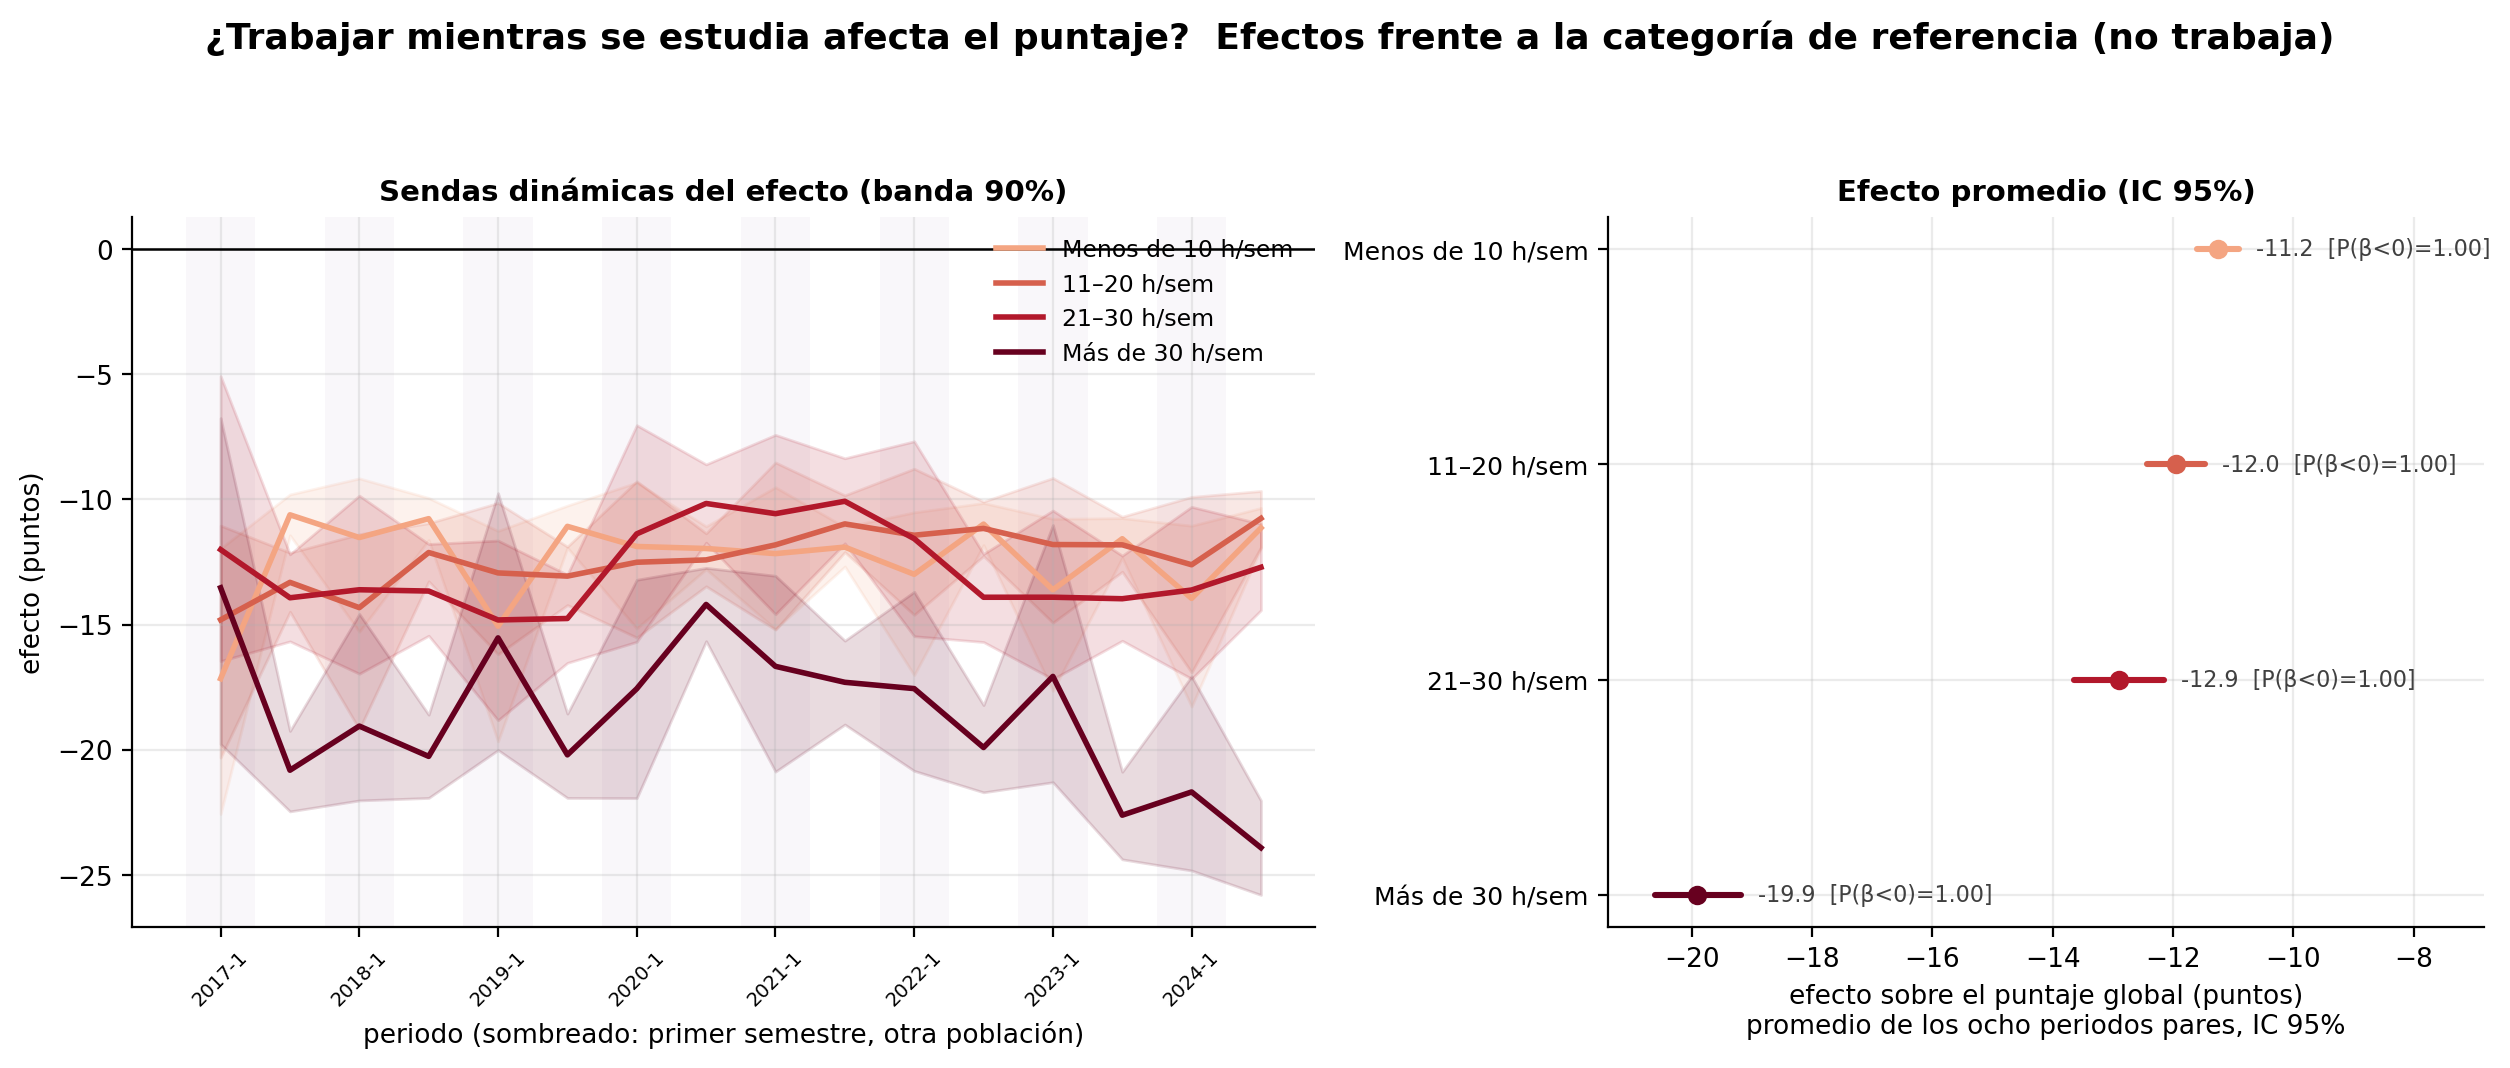

**figR2_padres.png**

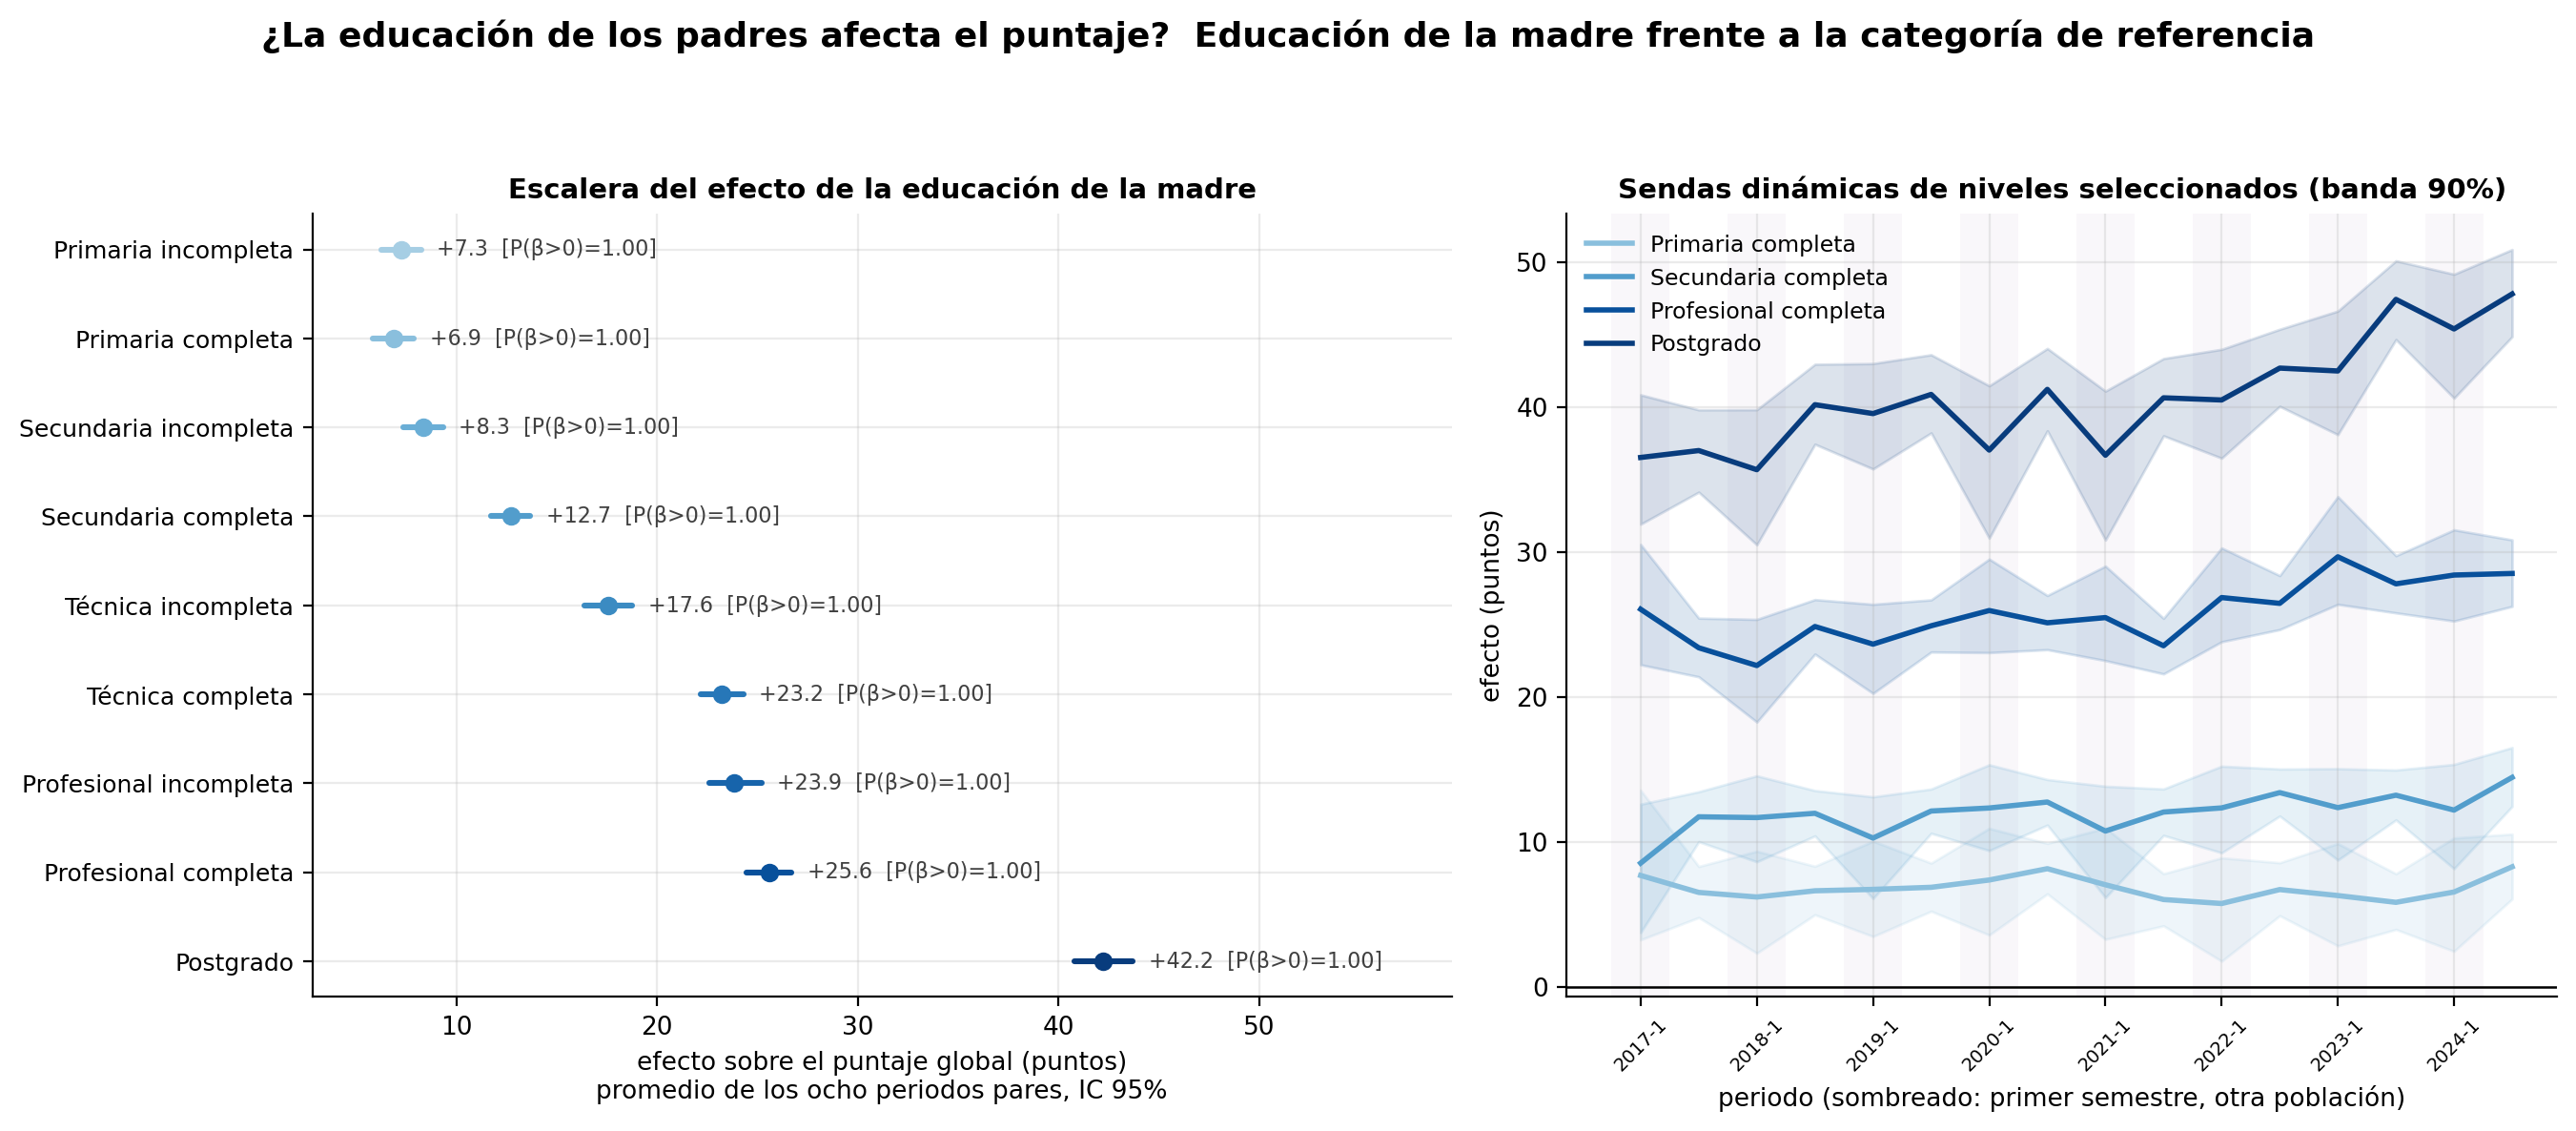

**figR3_violencia.png**

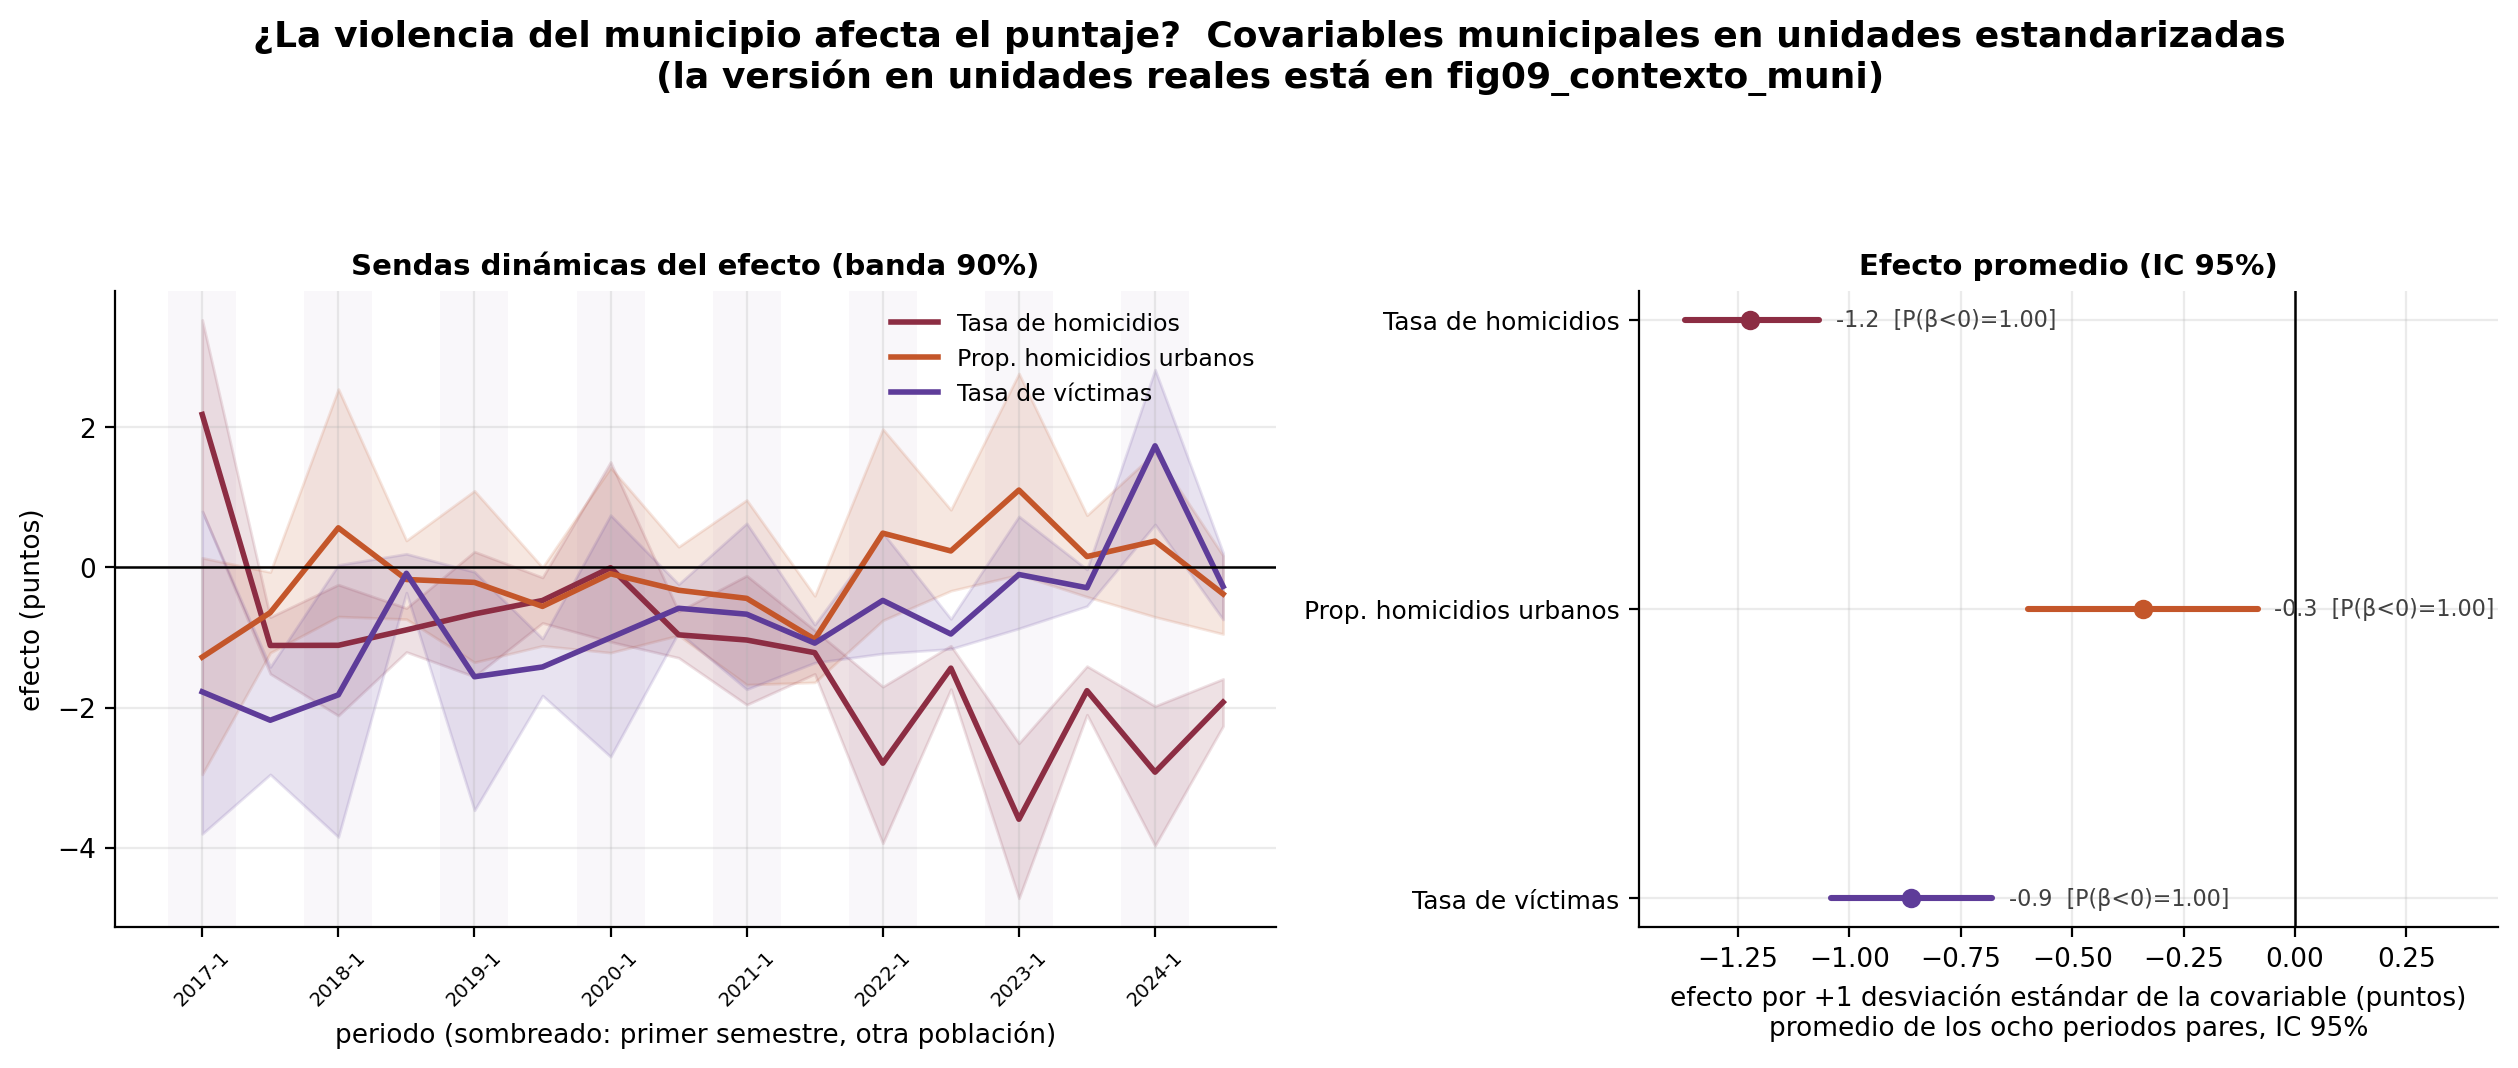

**figR4_panorama.png**

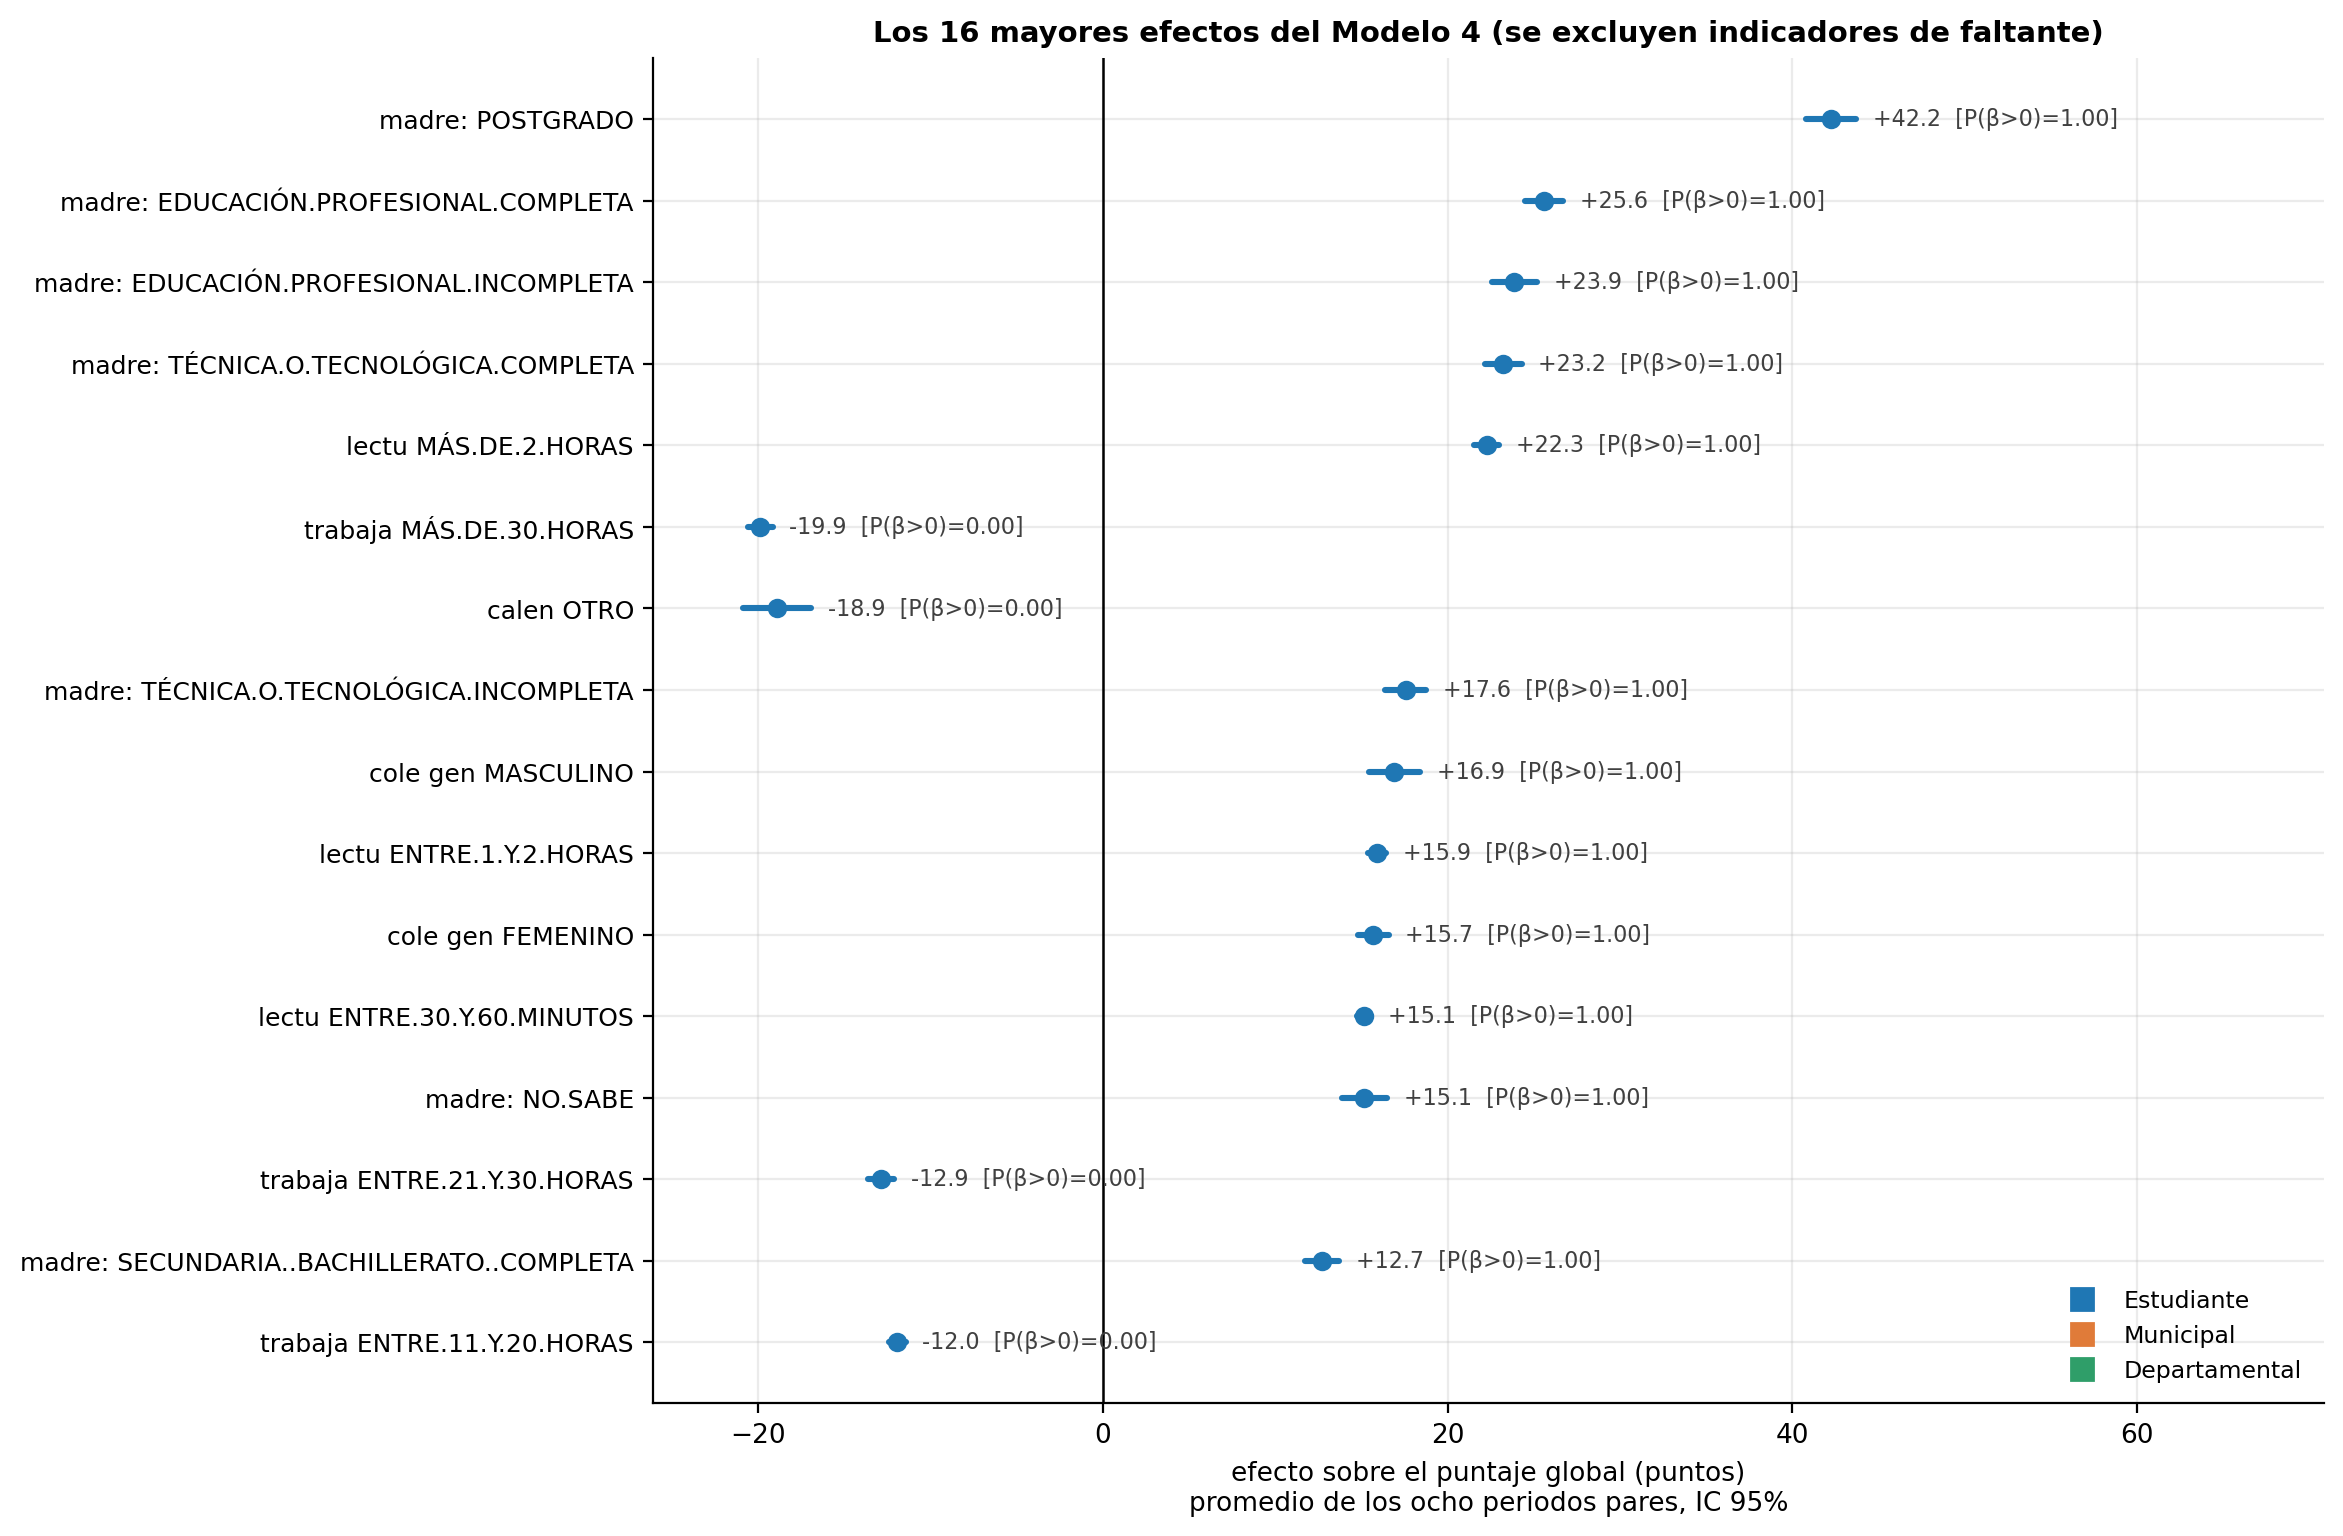

**figR5_hogar_colegio.png**

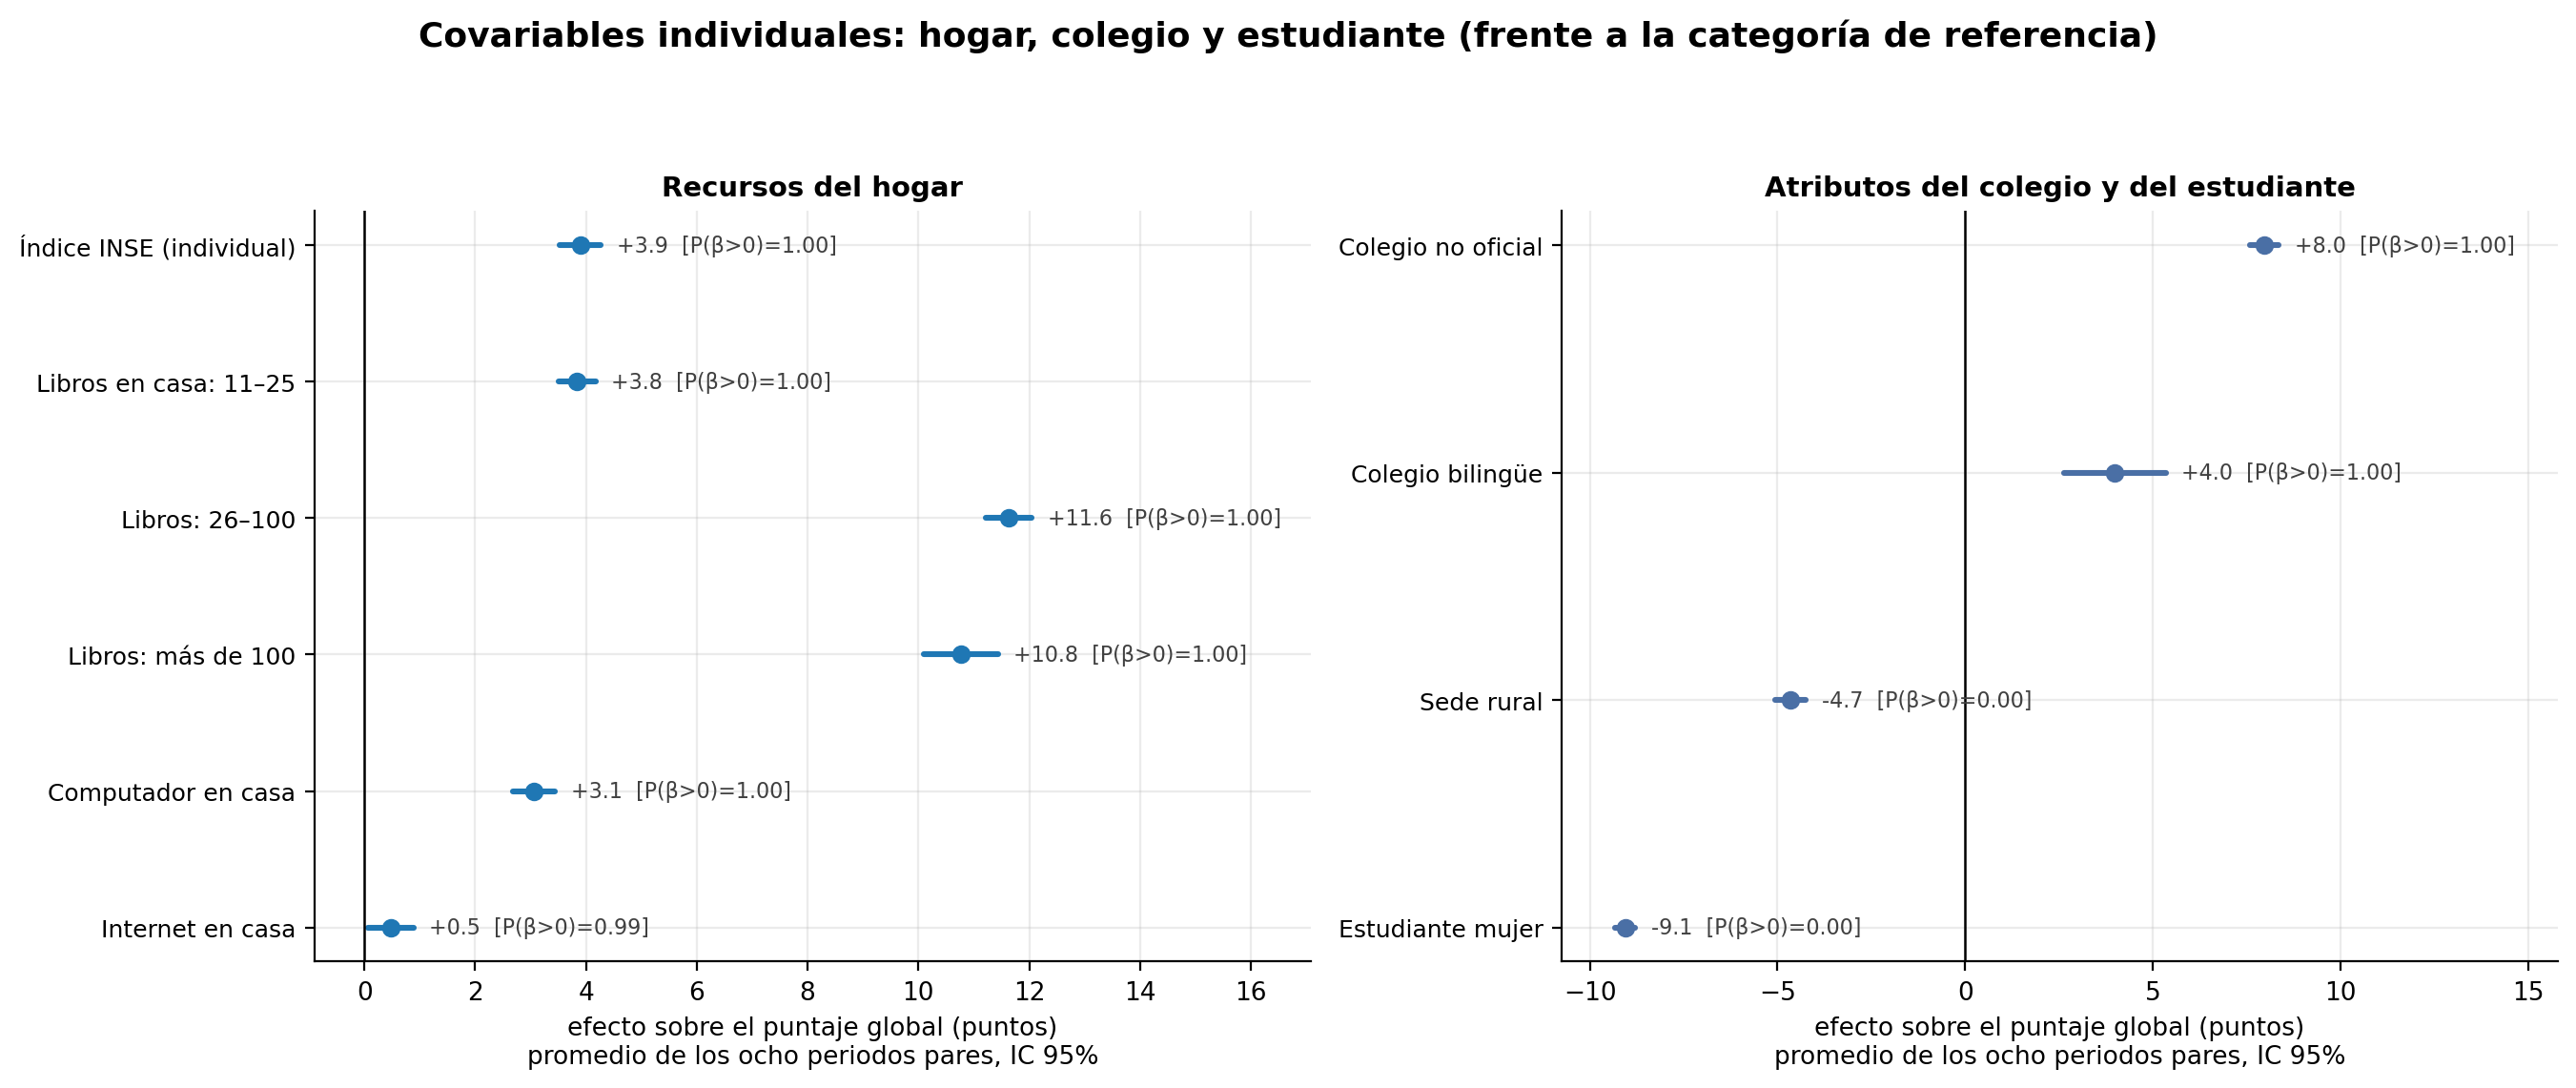

**figR6_calendario.png**

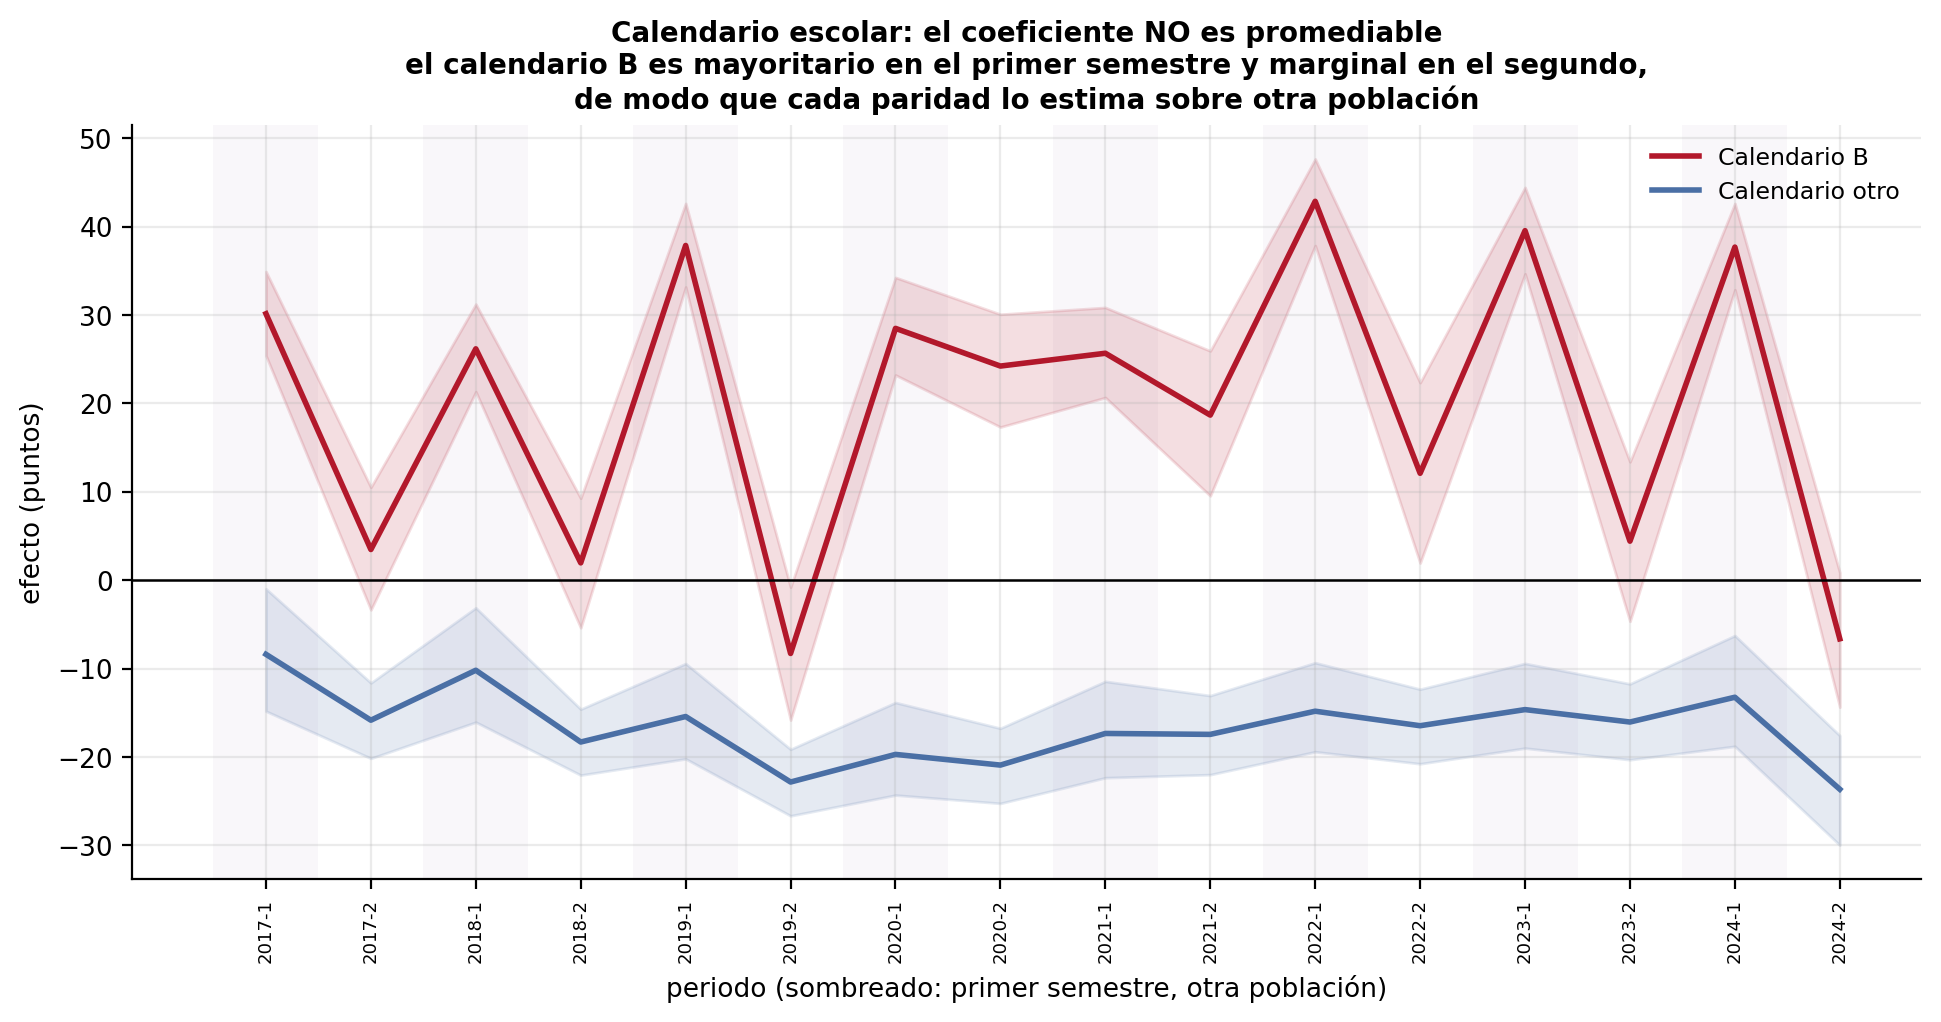

**fig01_encuadre.png**

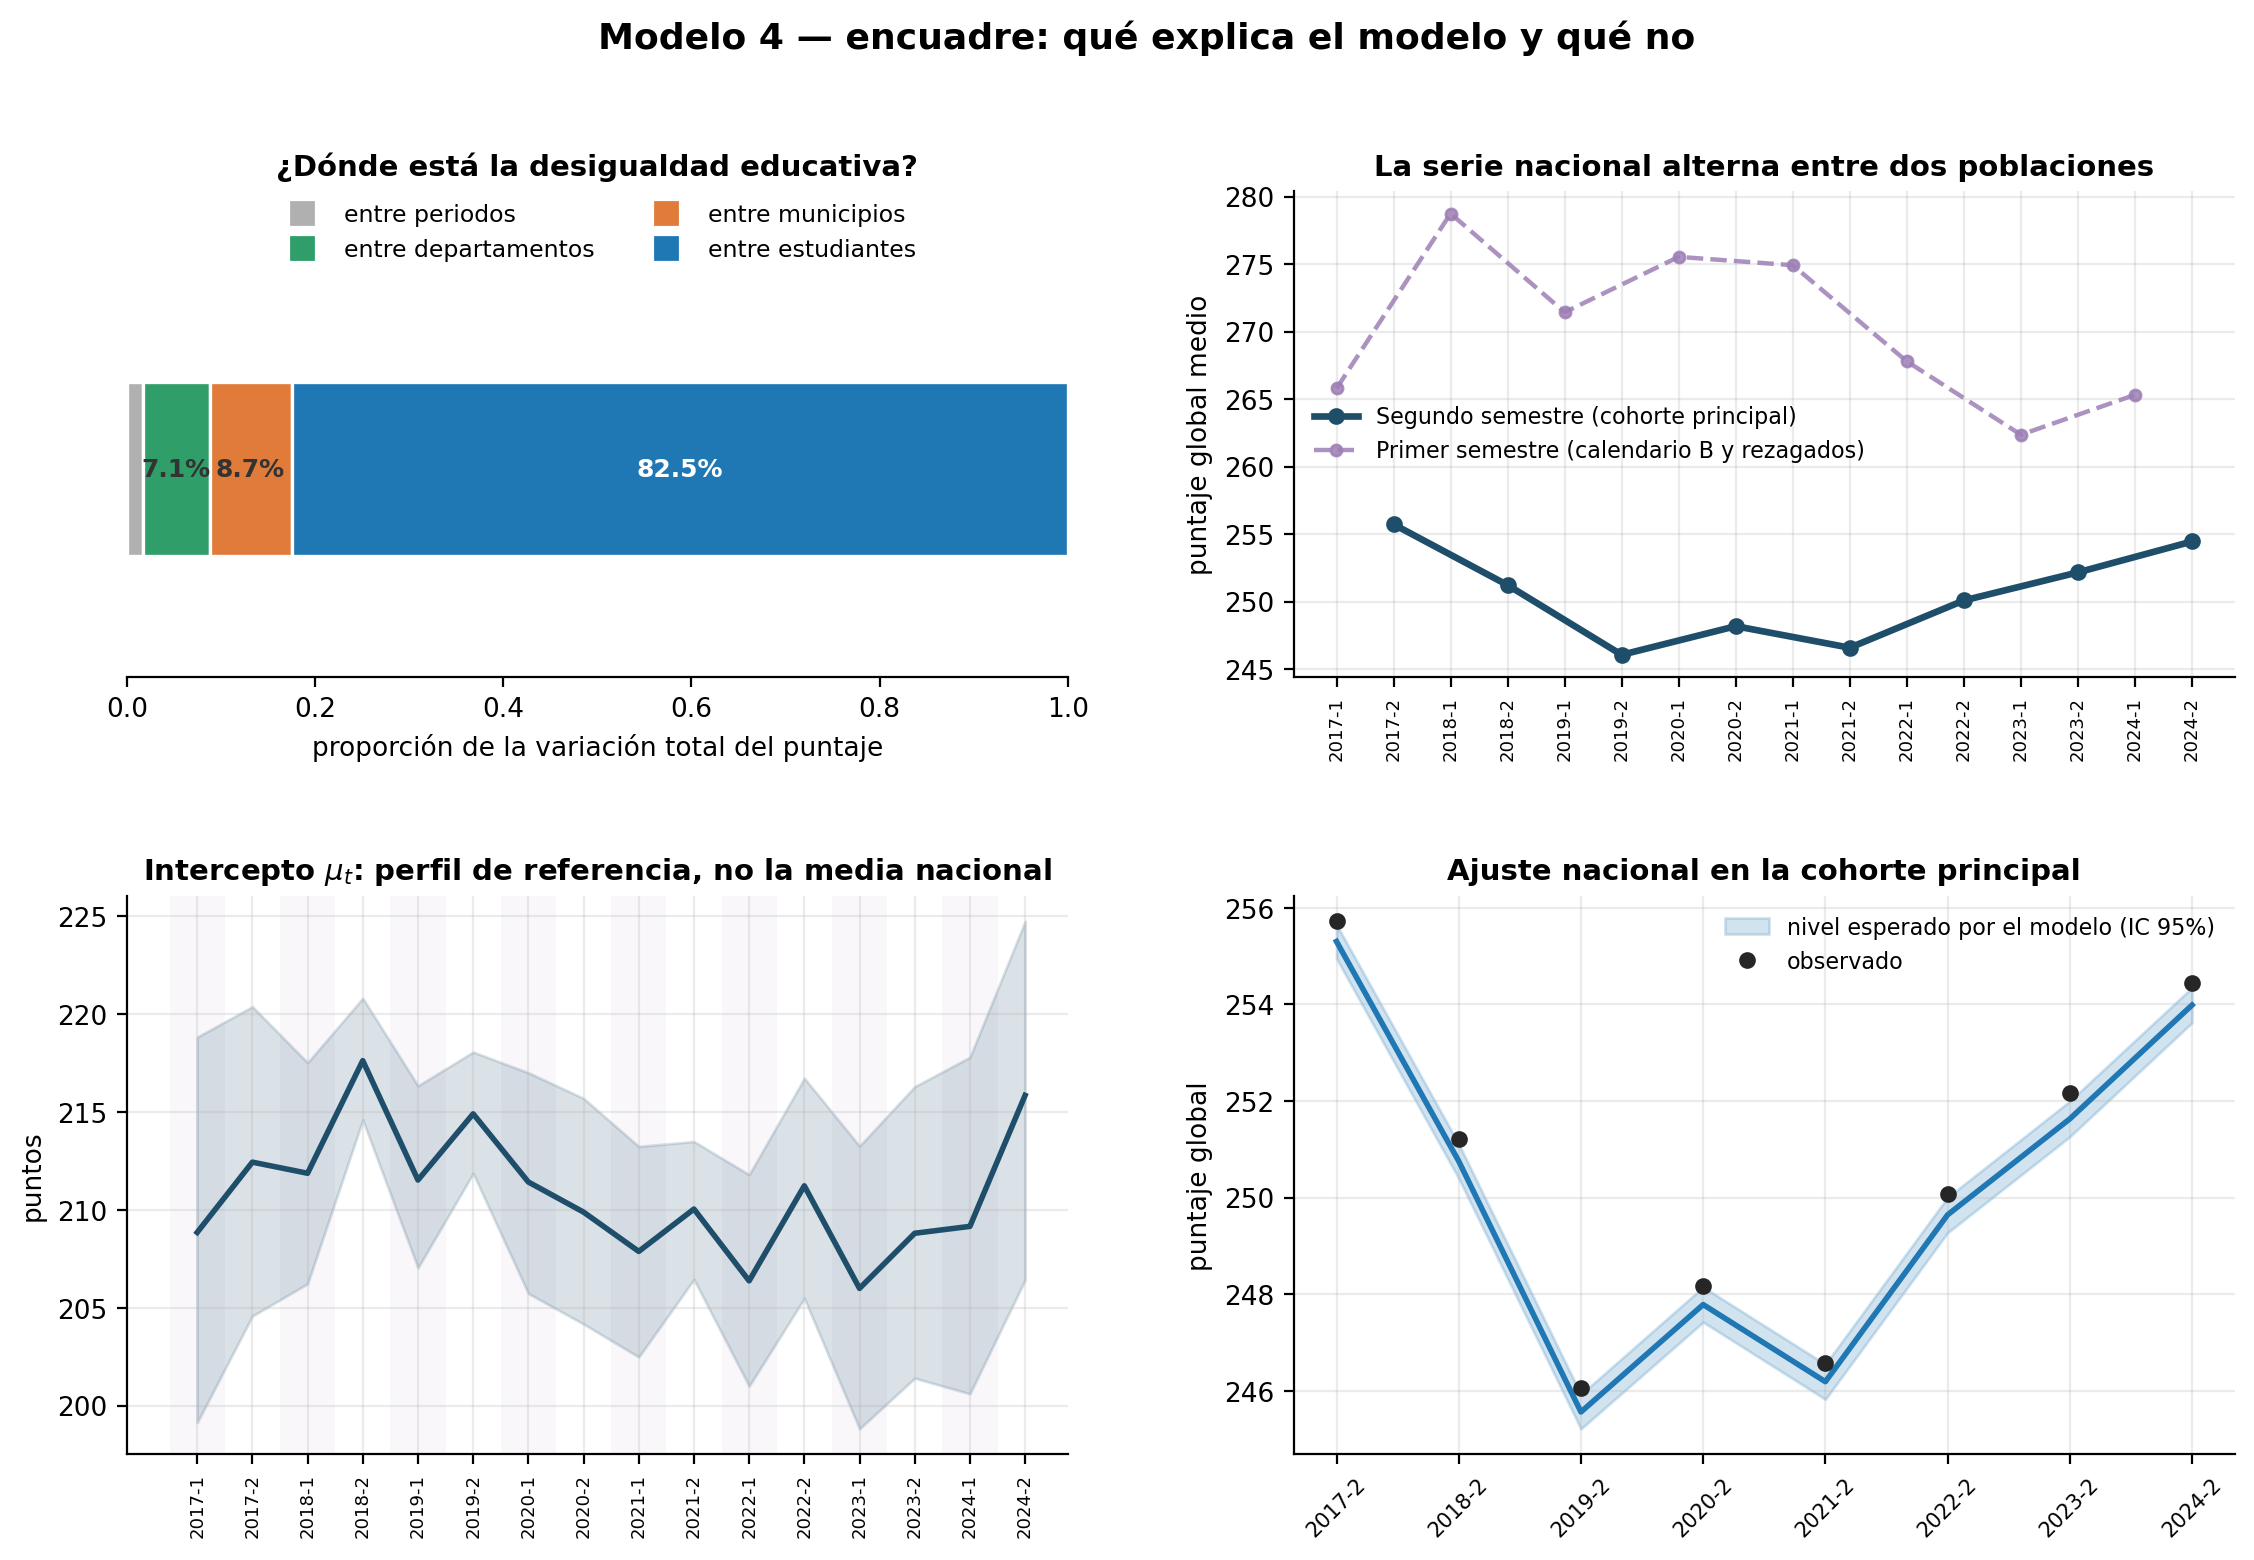

**fig02_nivel_depto.png**

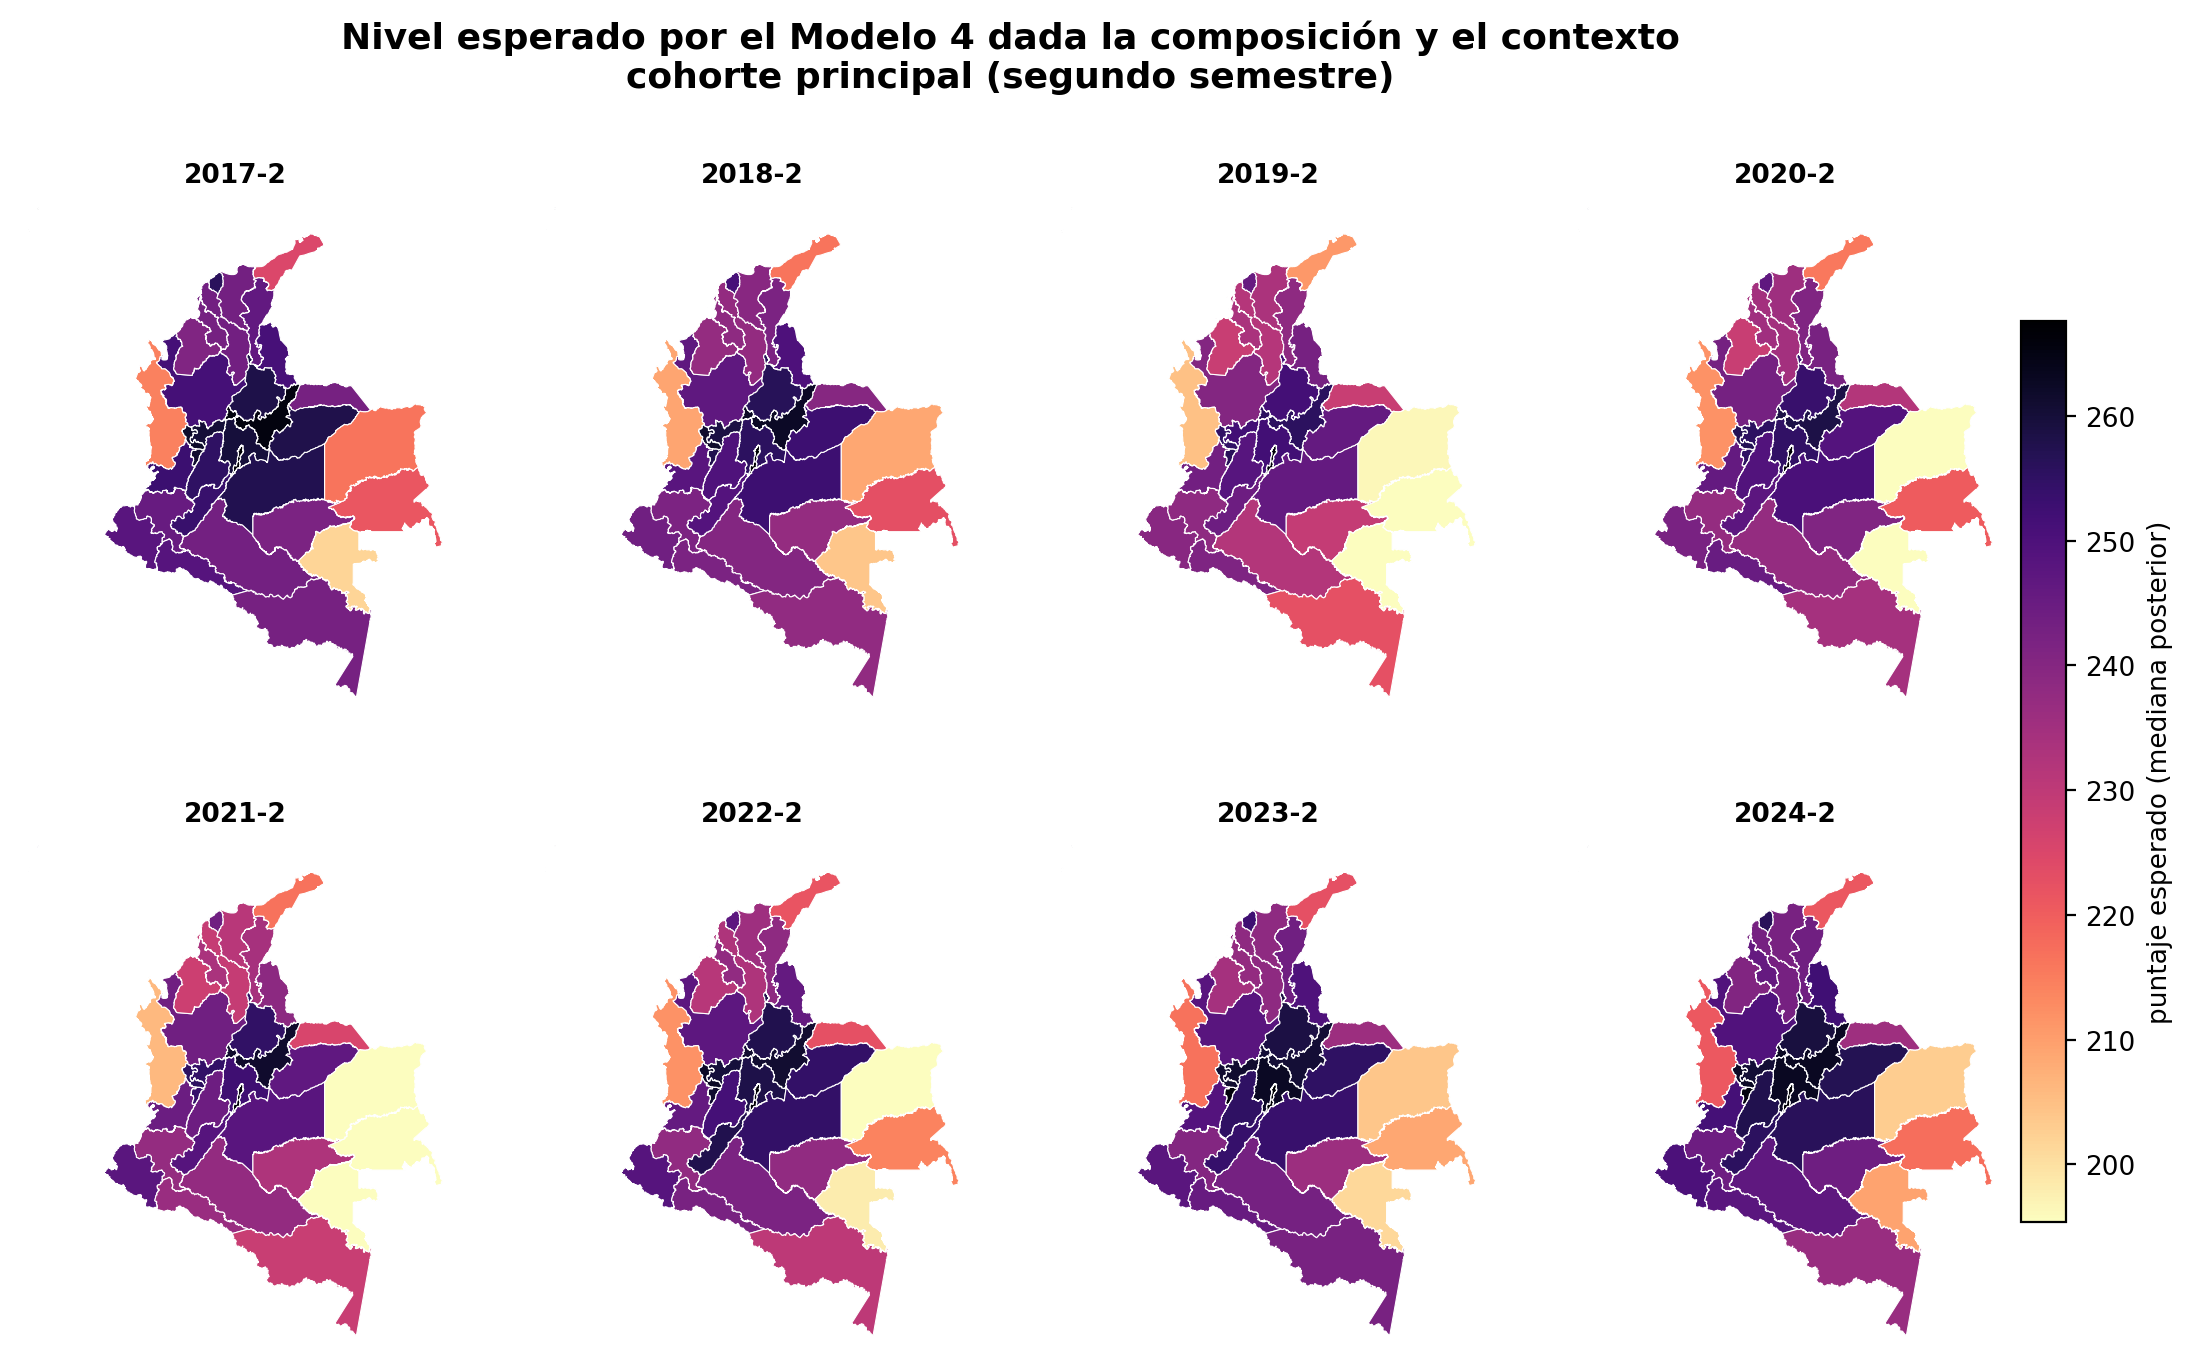

**fig03_residuo.png**

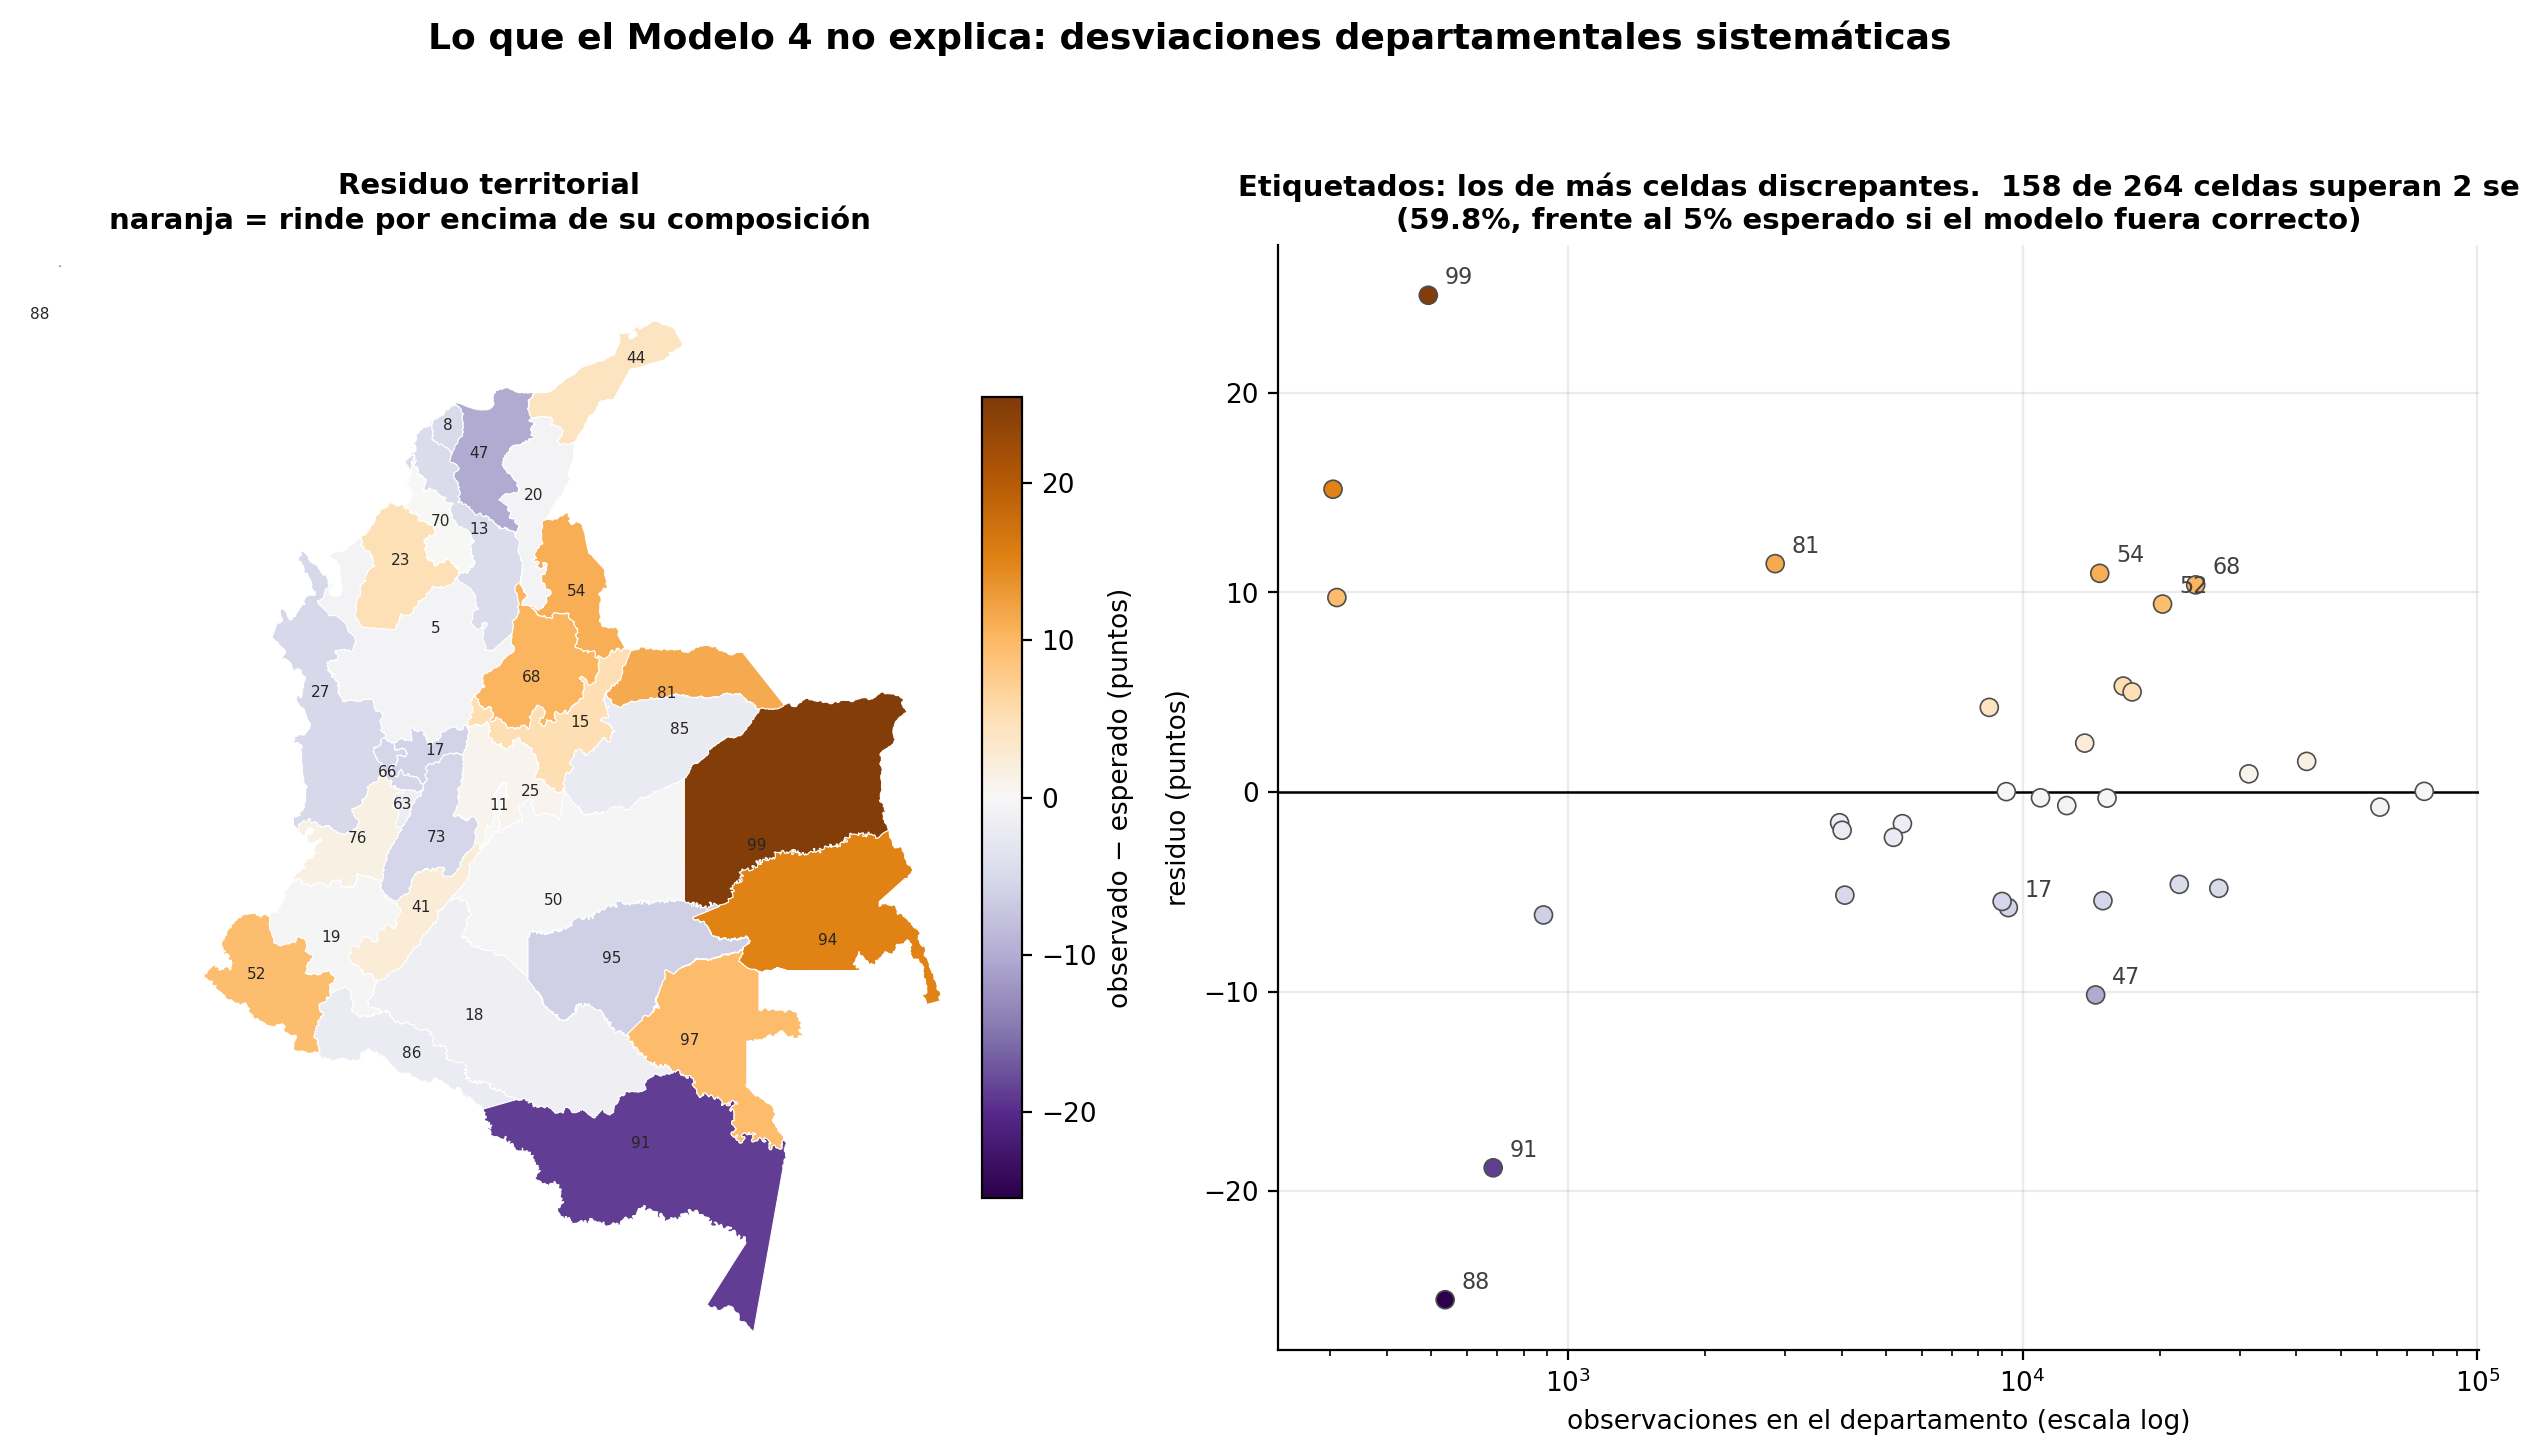

**fig04_heatmap.png**

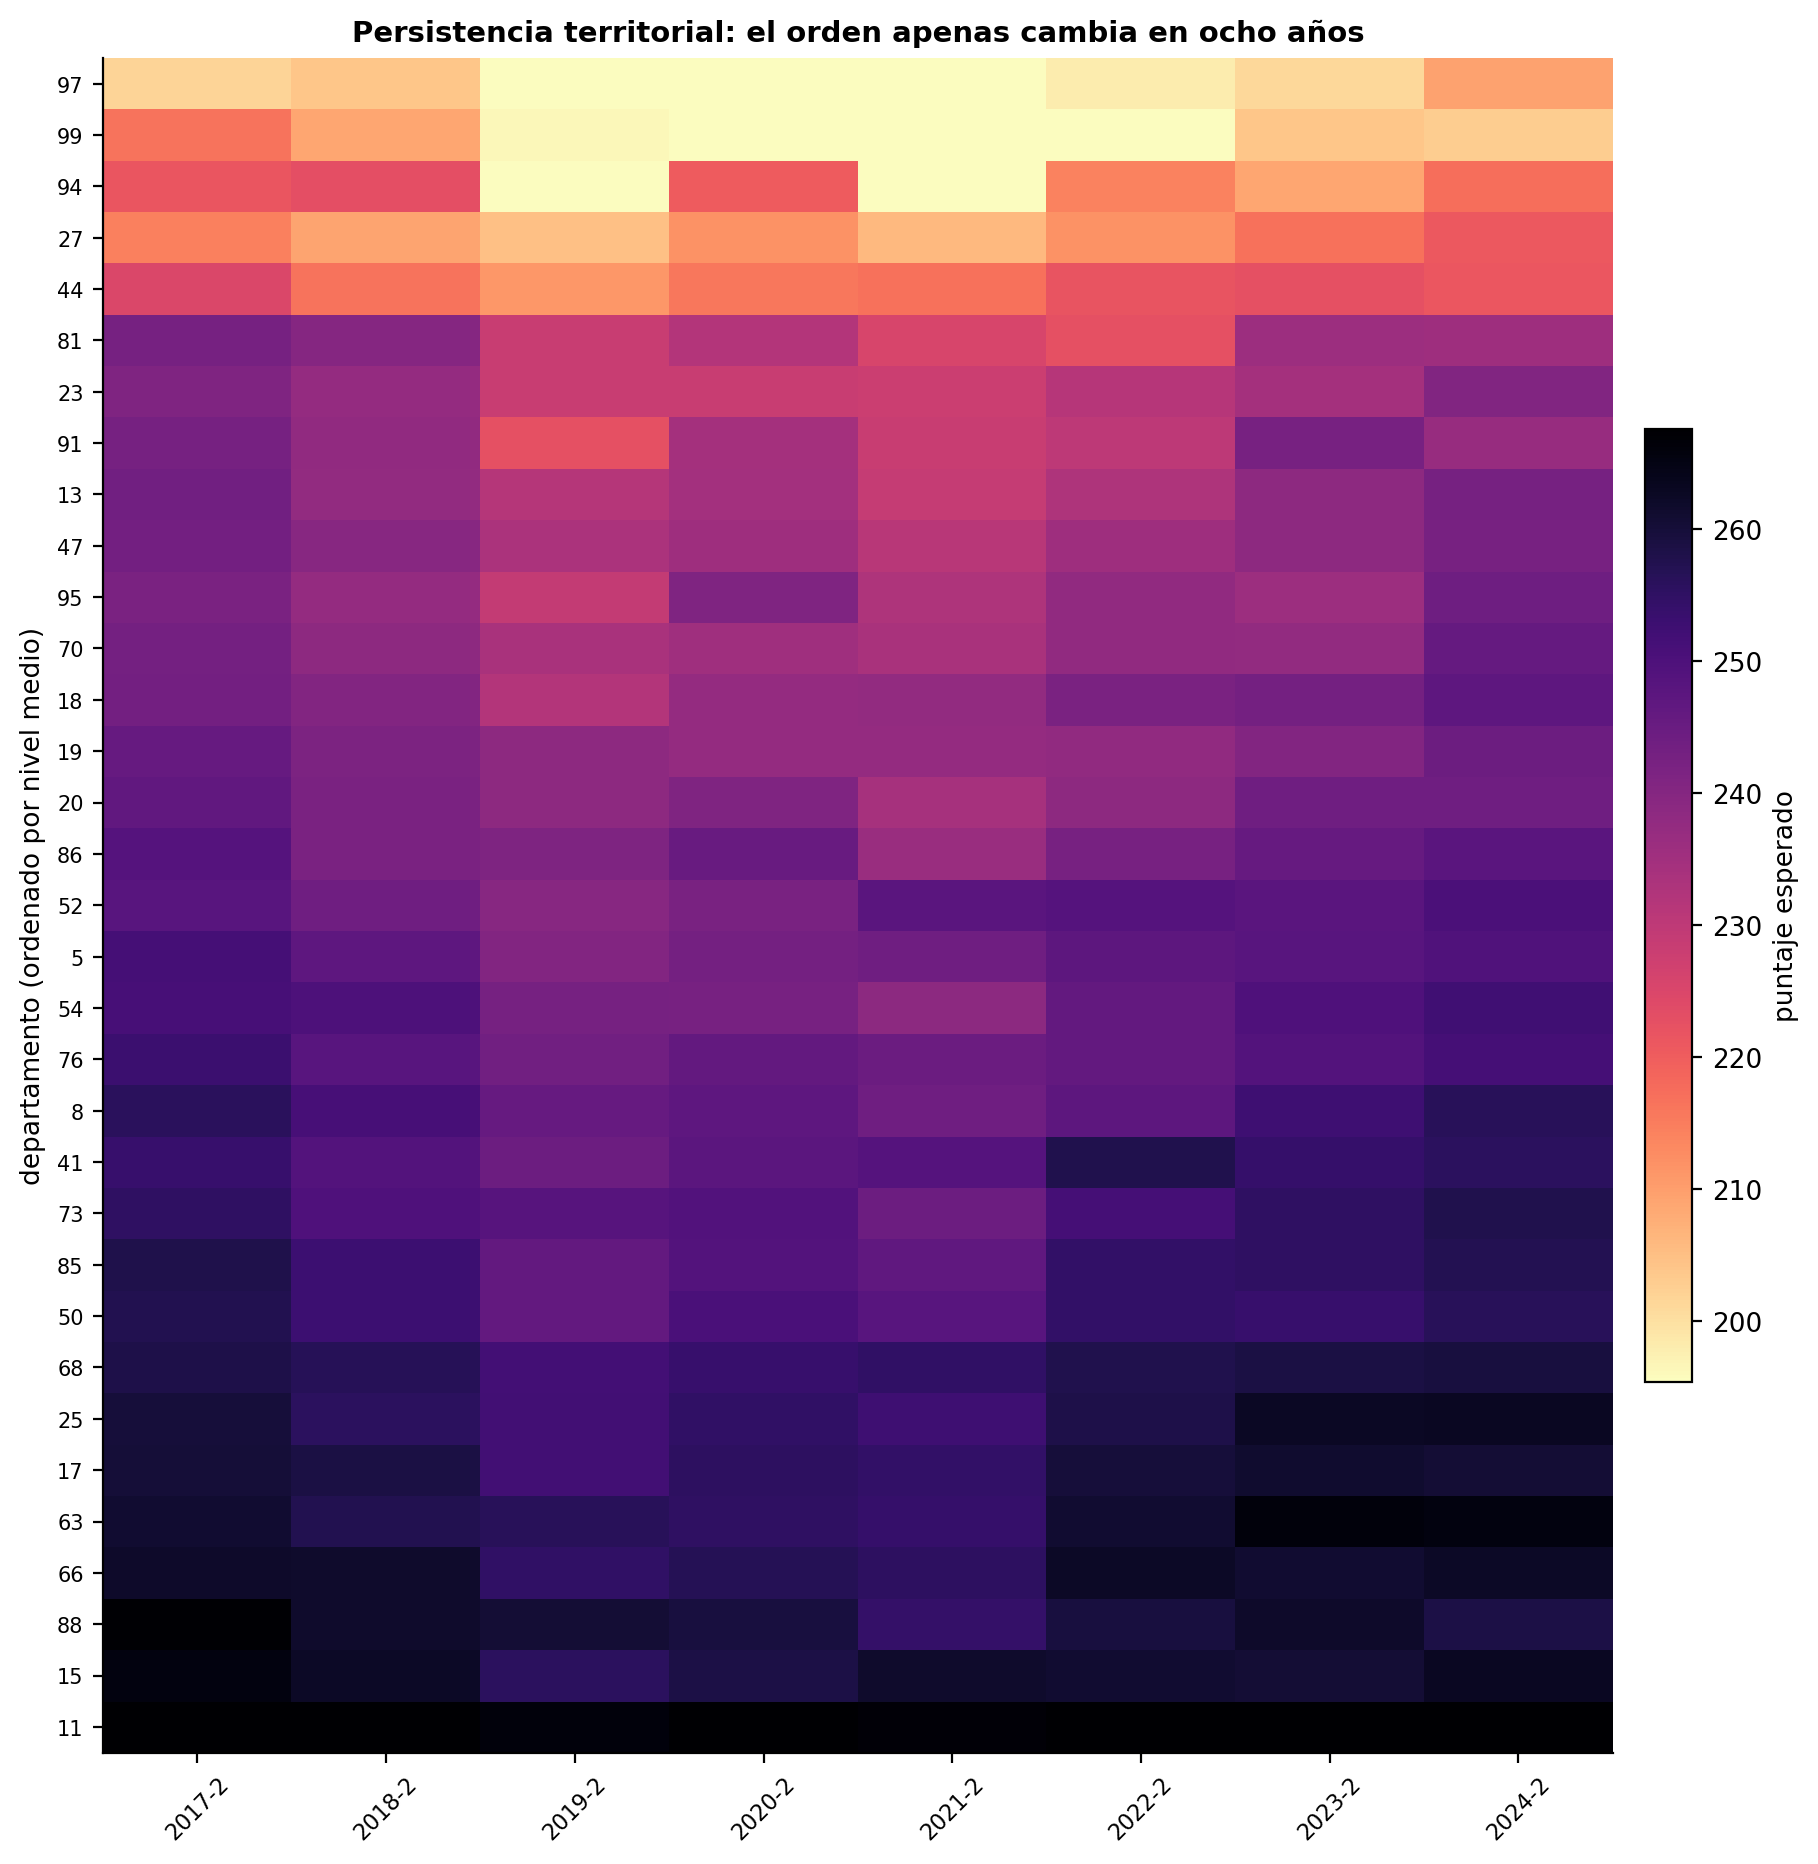

**fig05_convergencia.png**

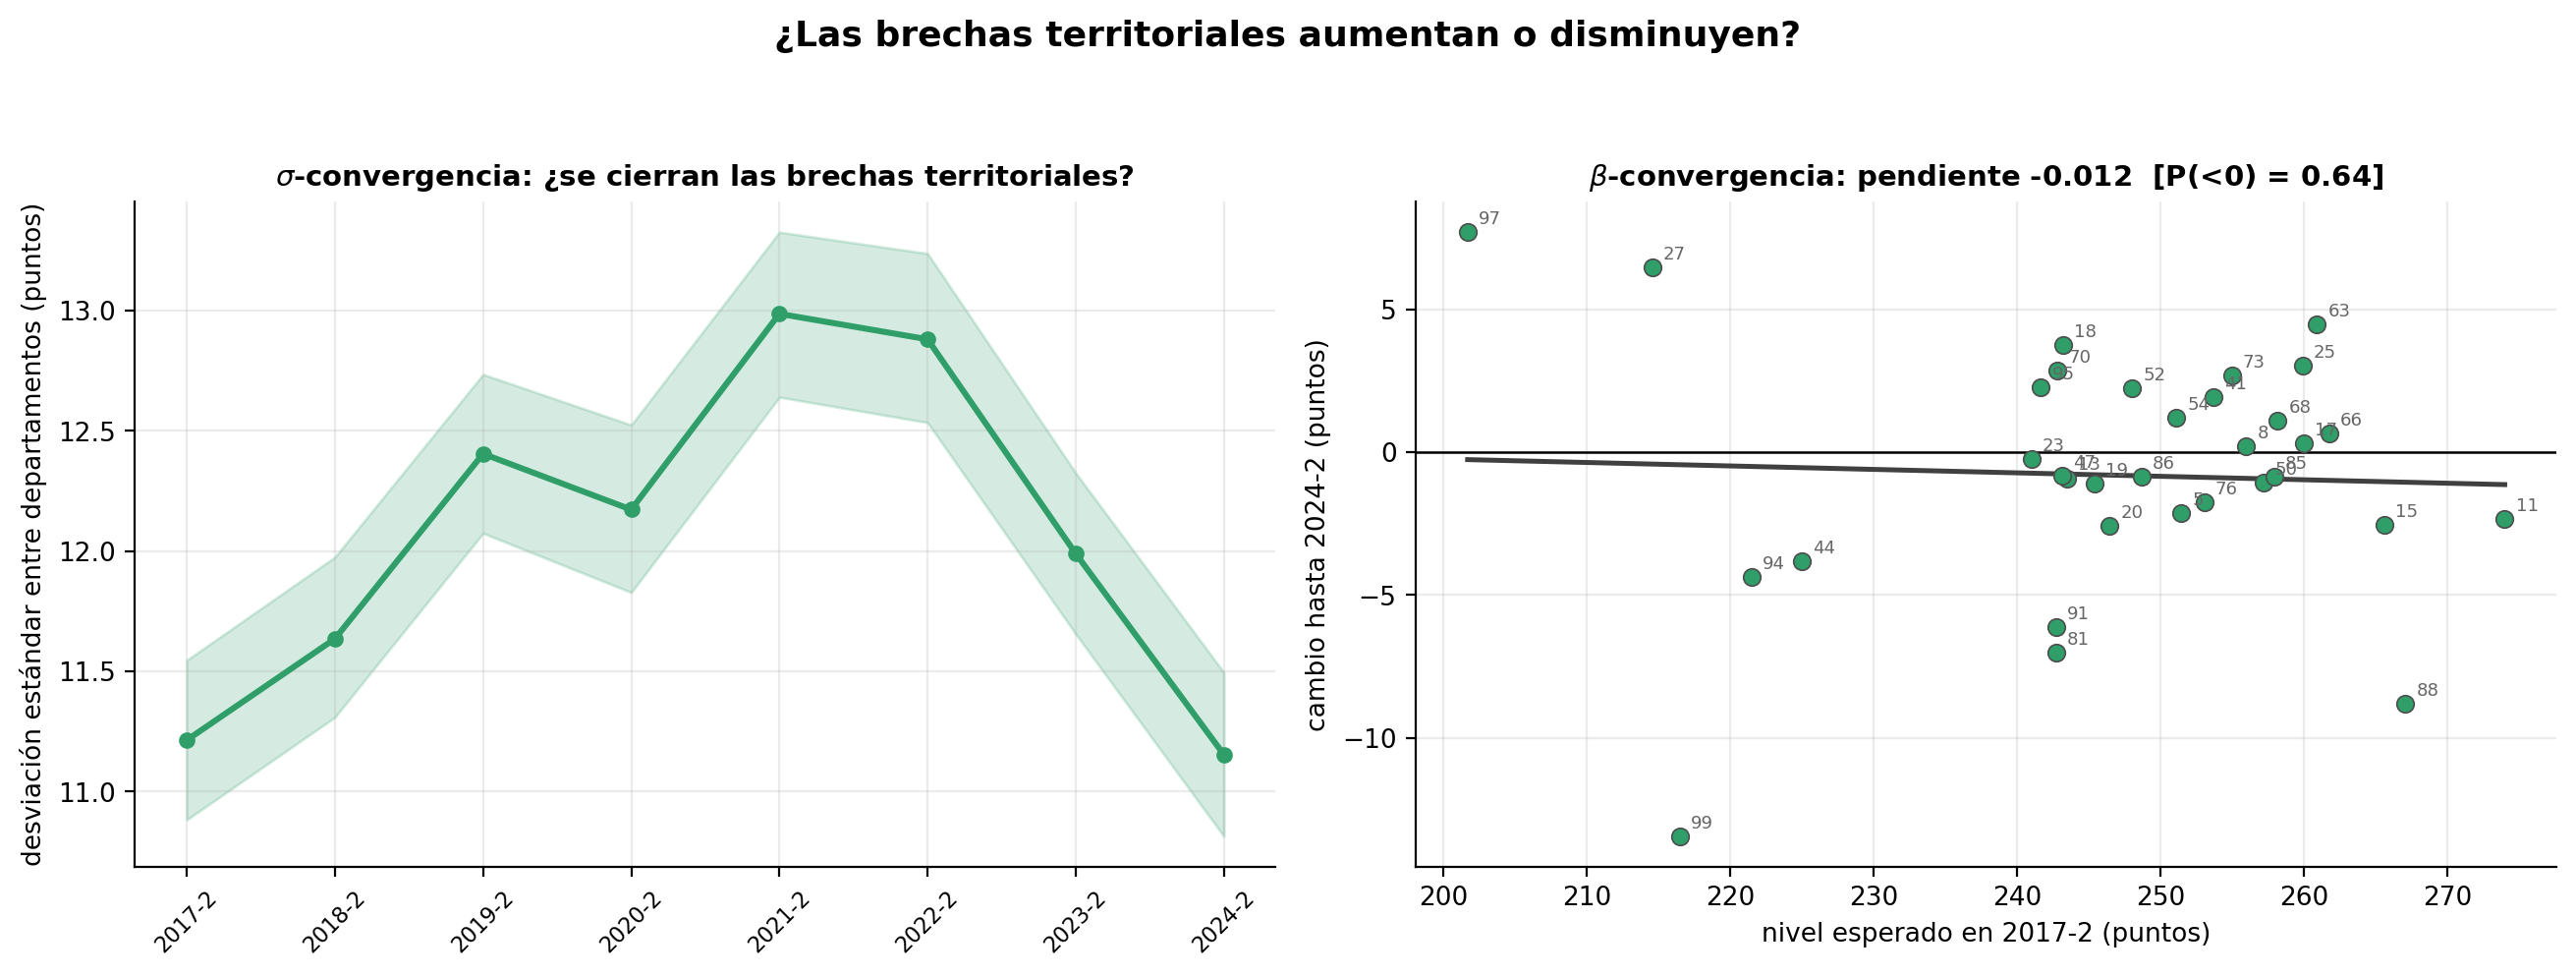

**fig06_nivel_muni.png**

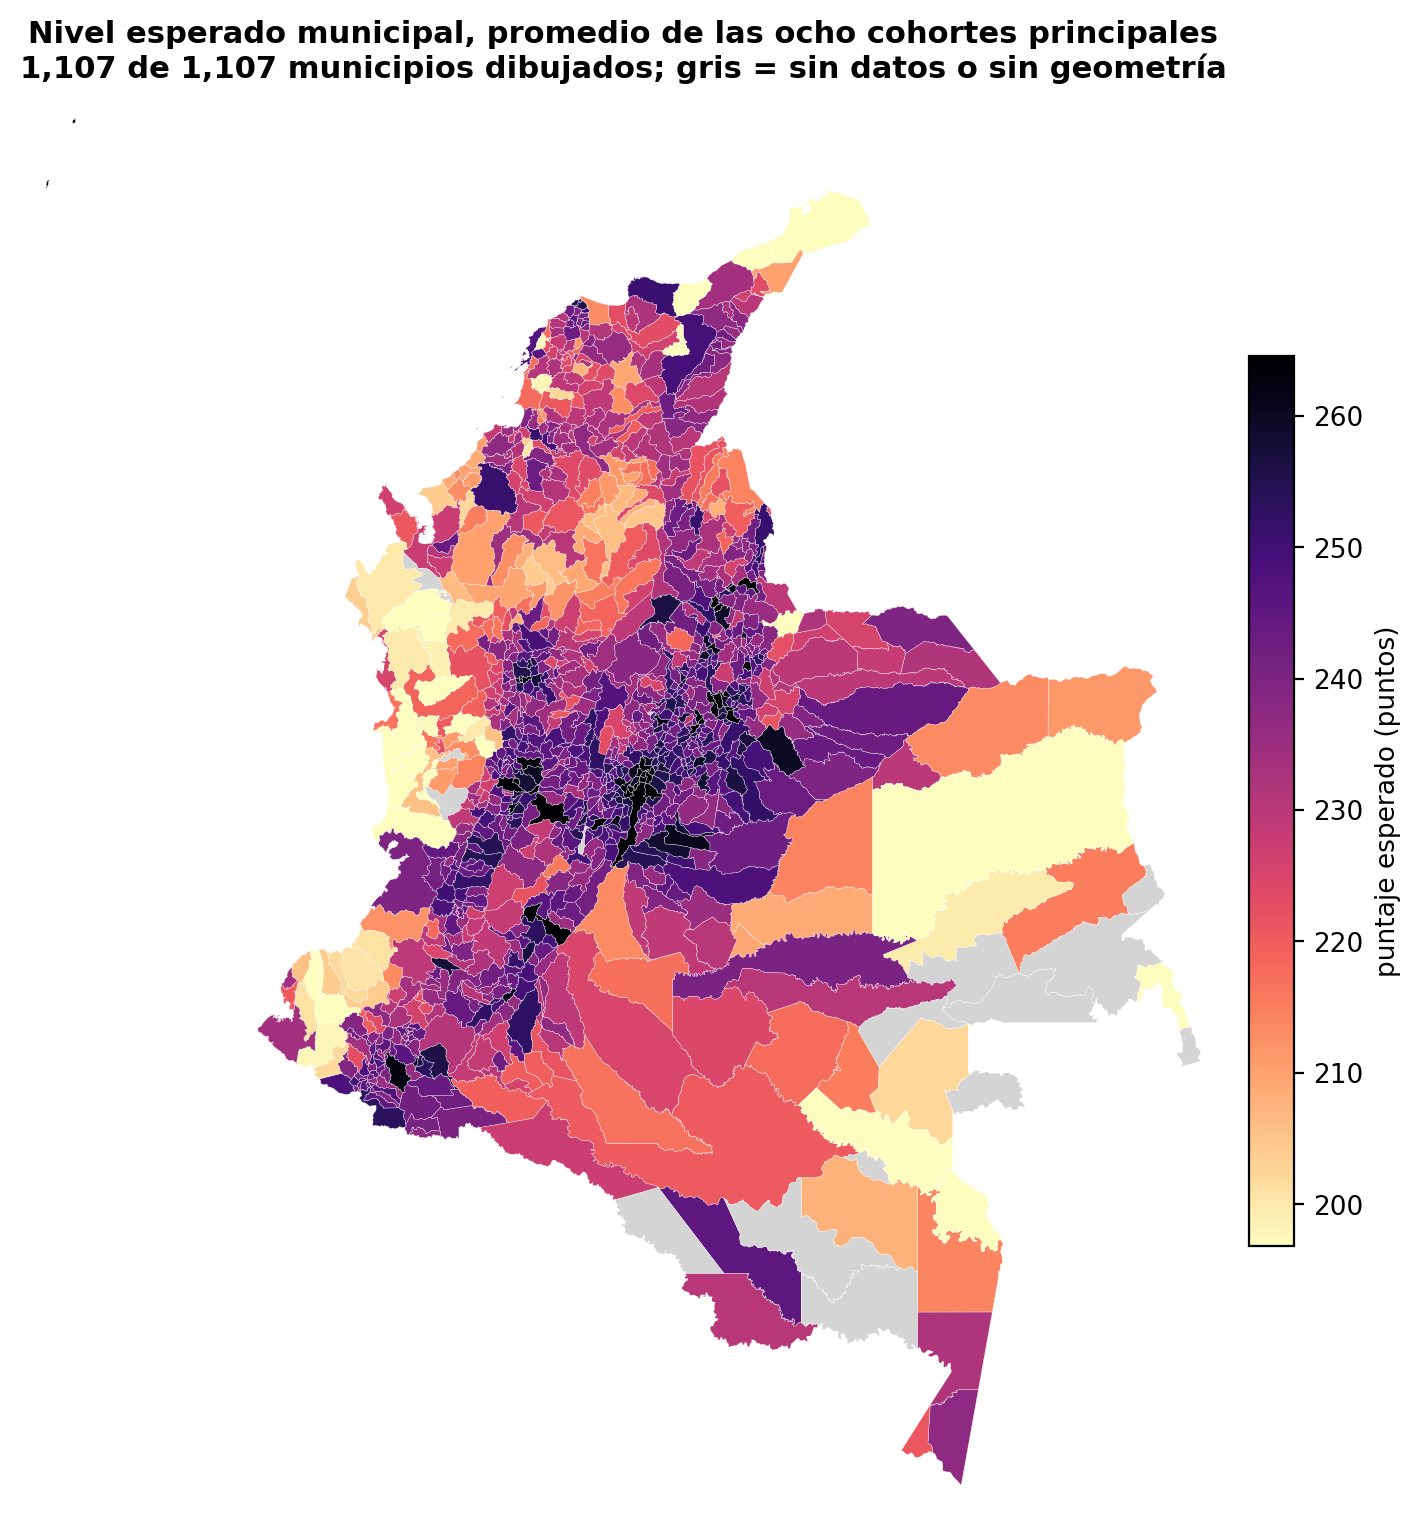

**fig07_alimentacion.png**

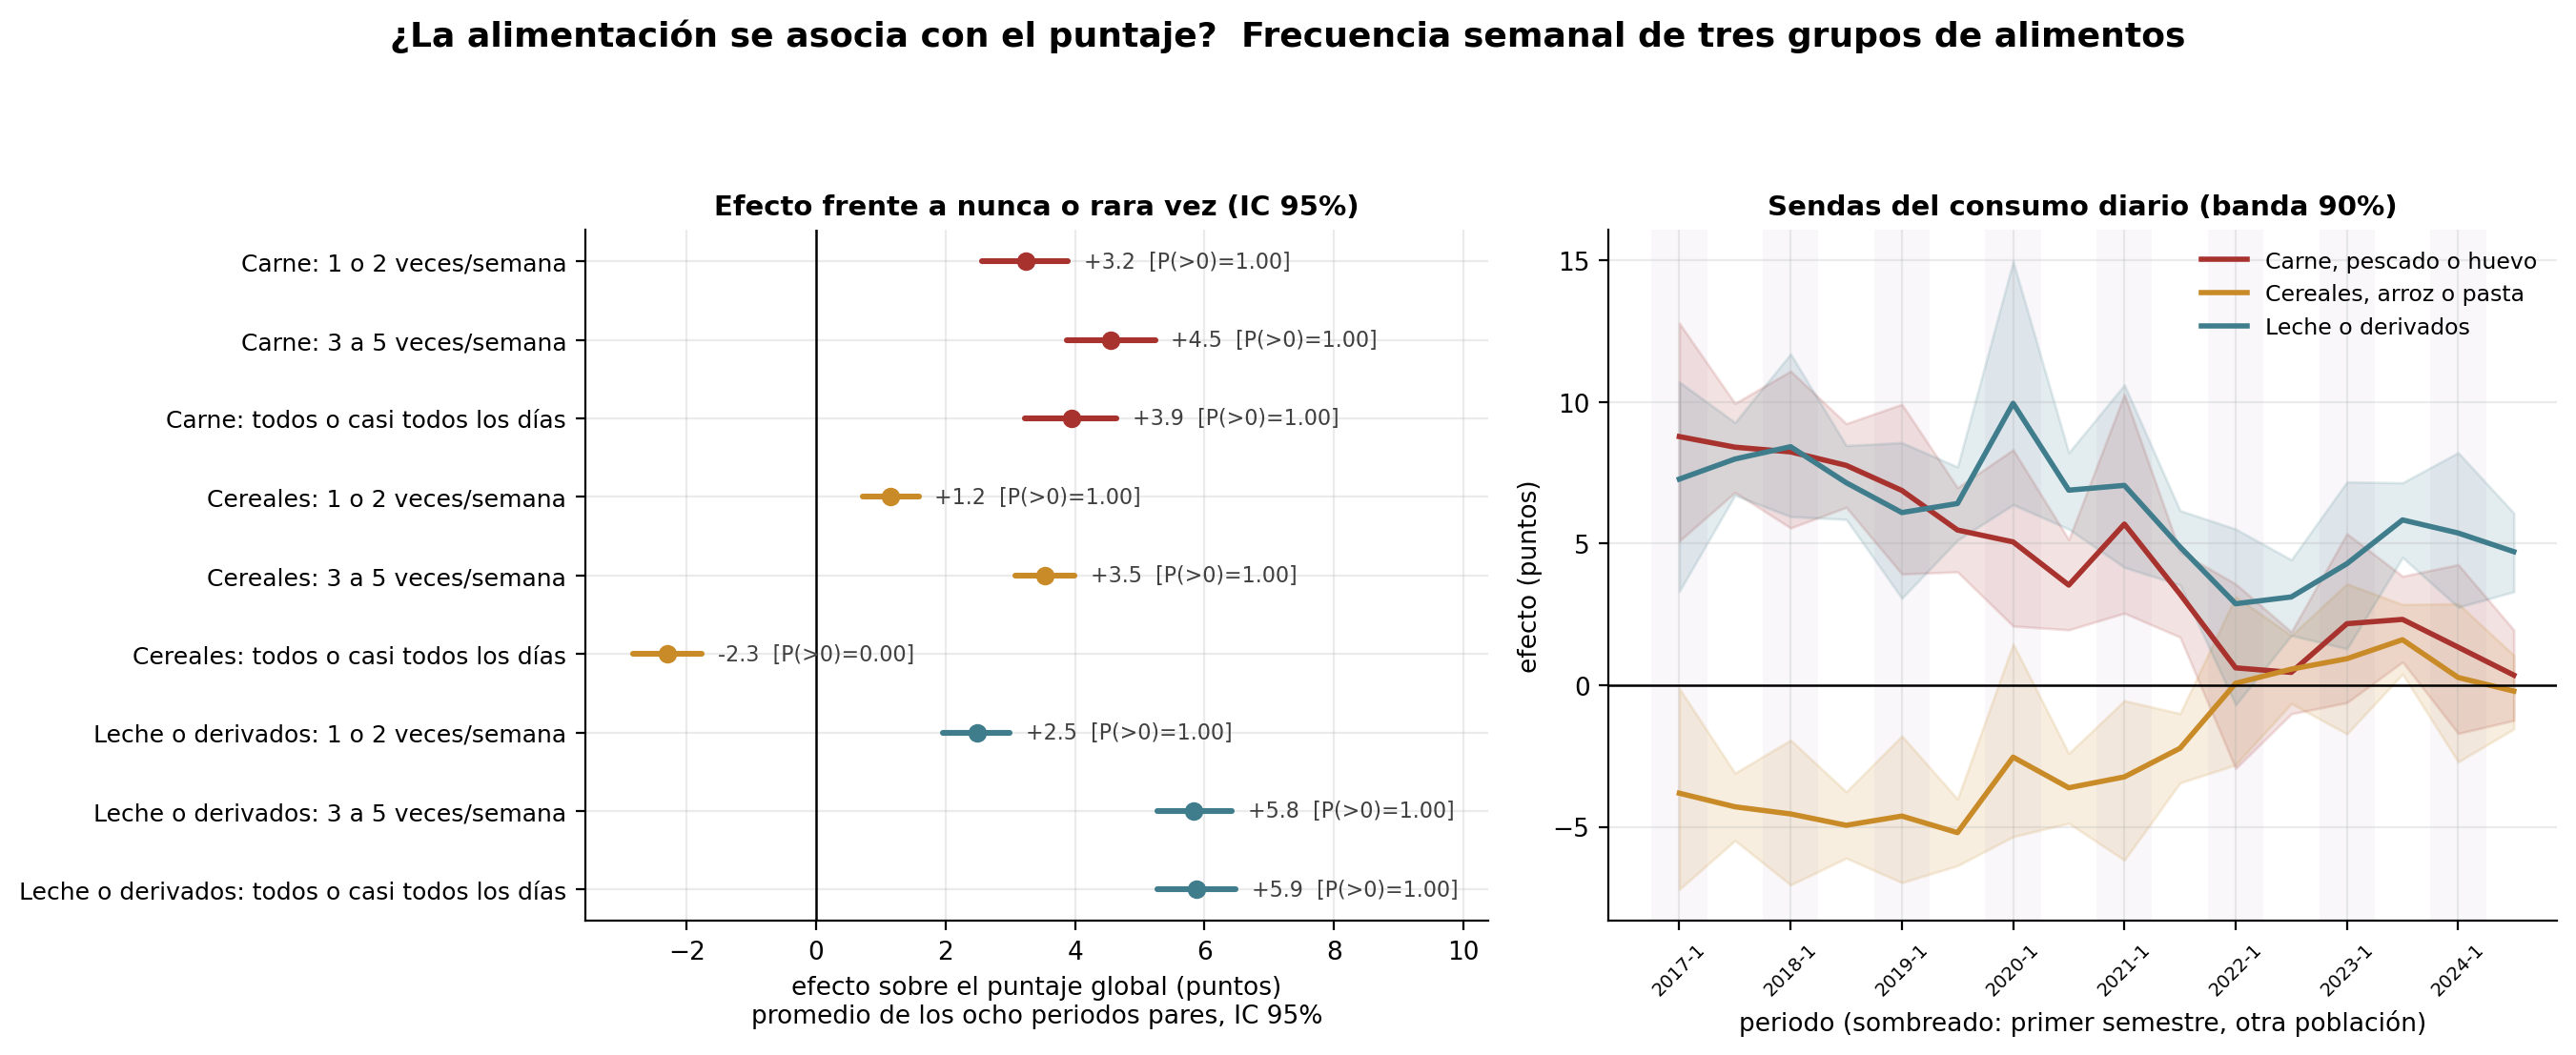

**fig08_lectura_internet.png**

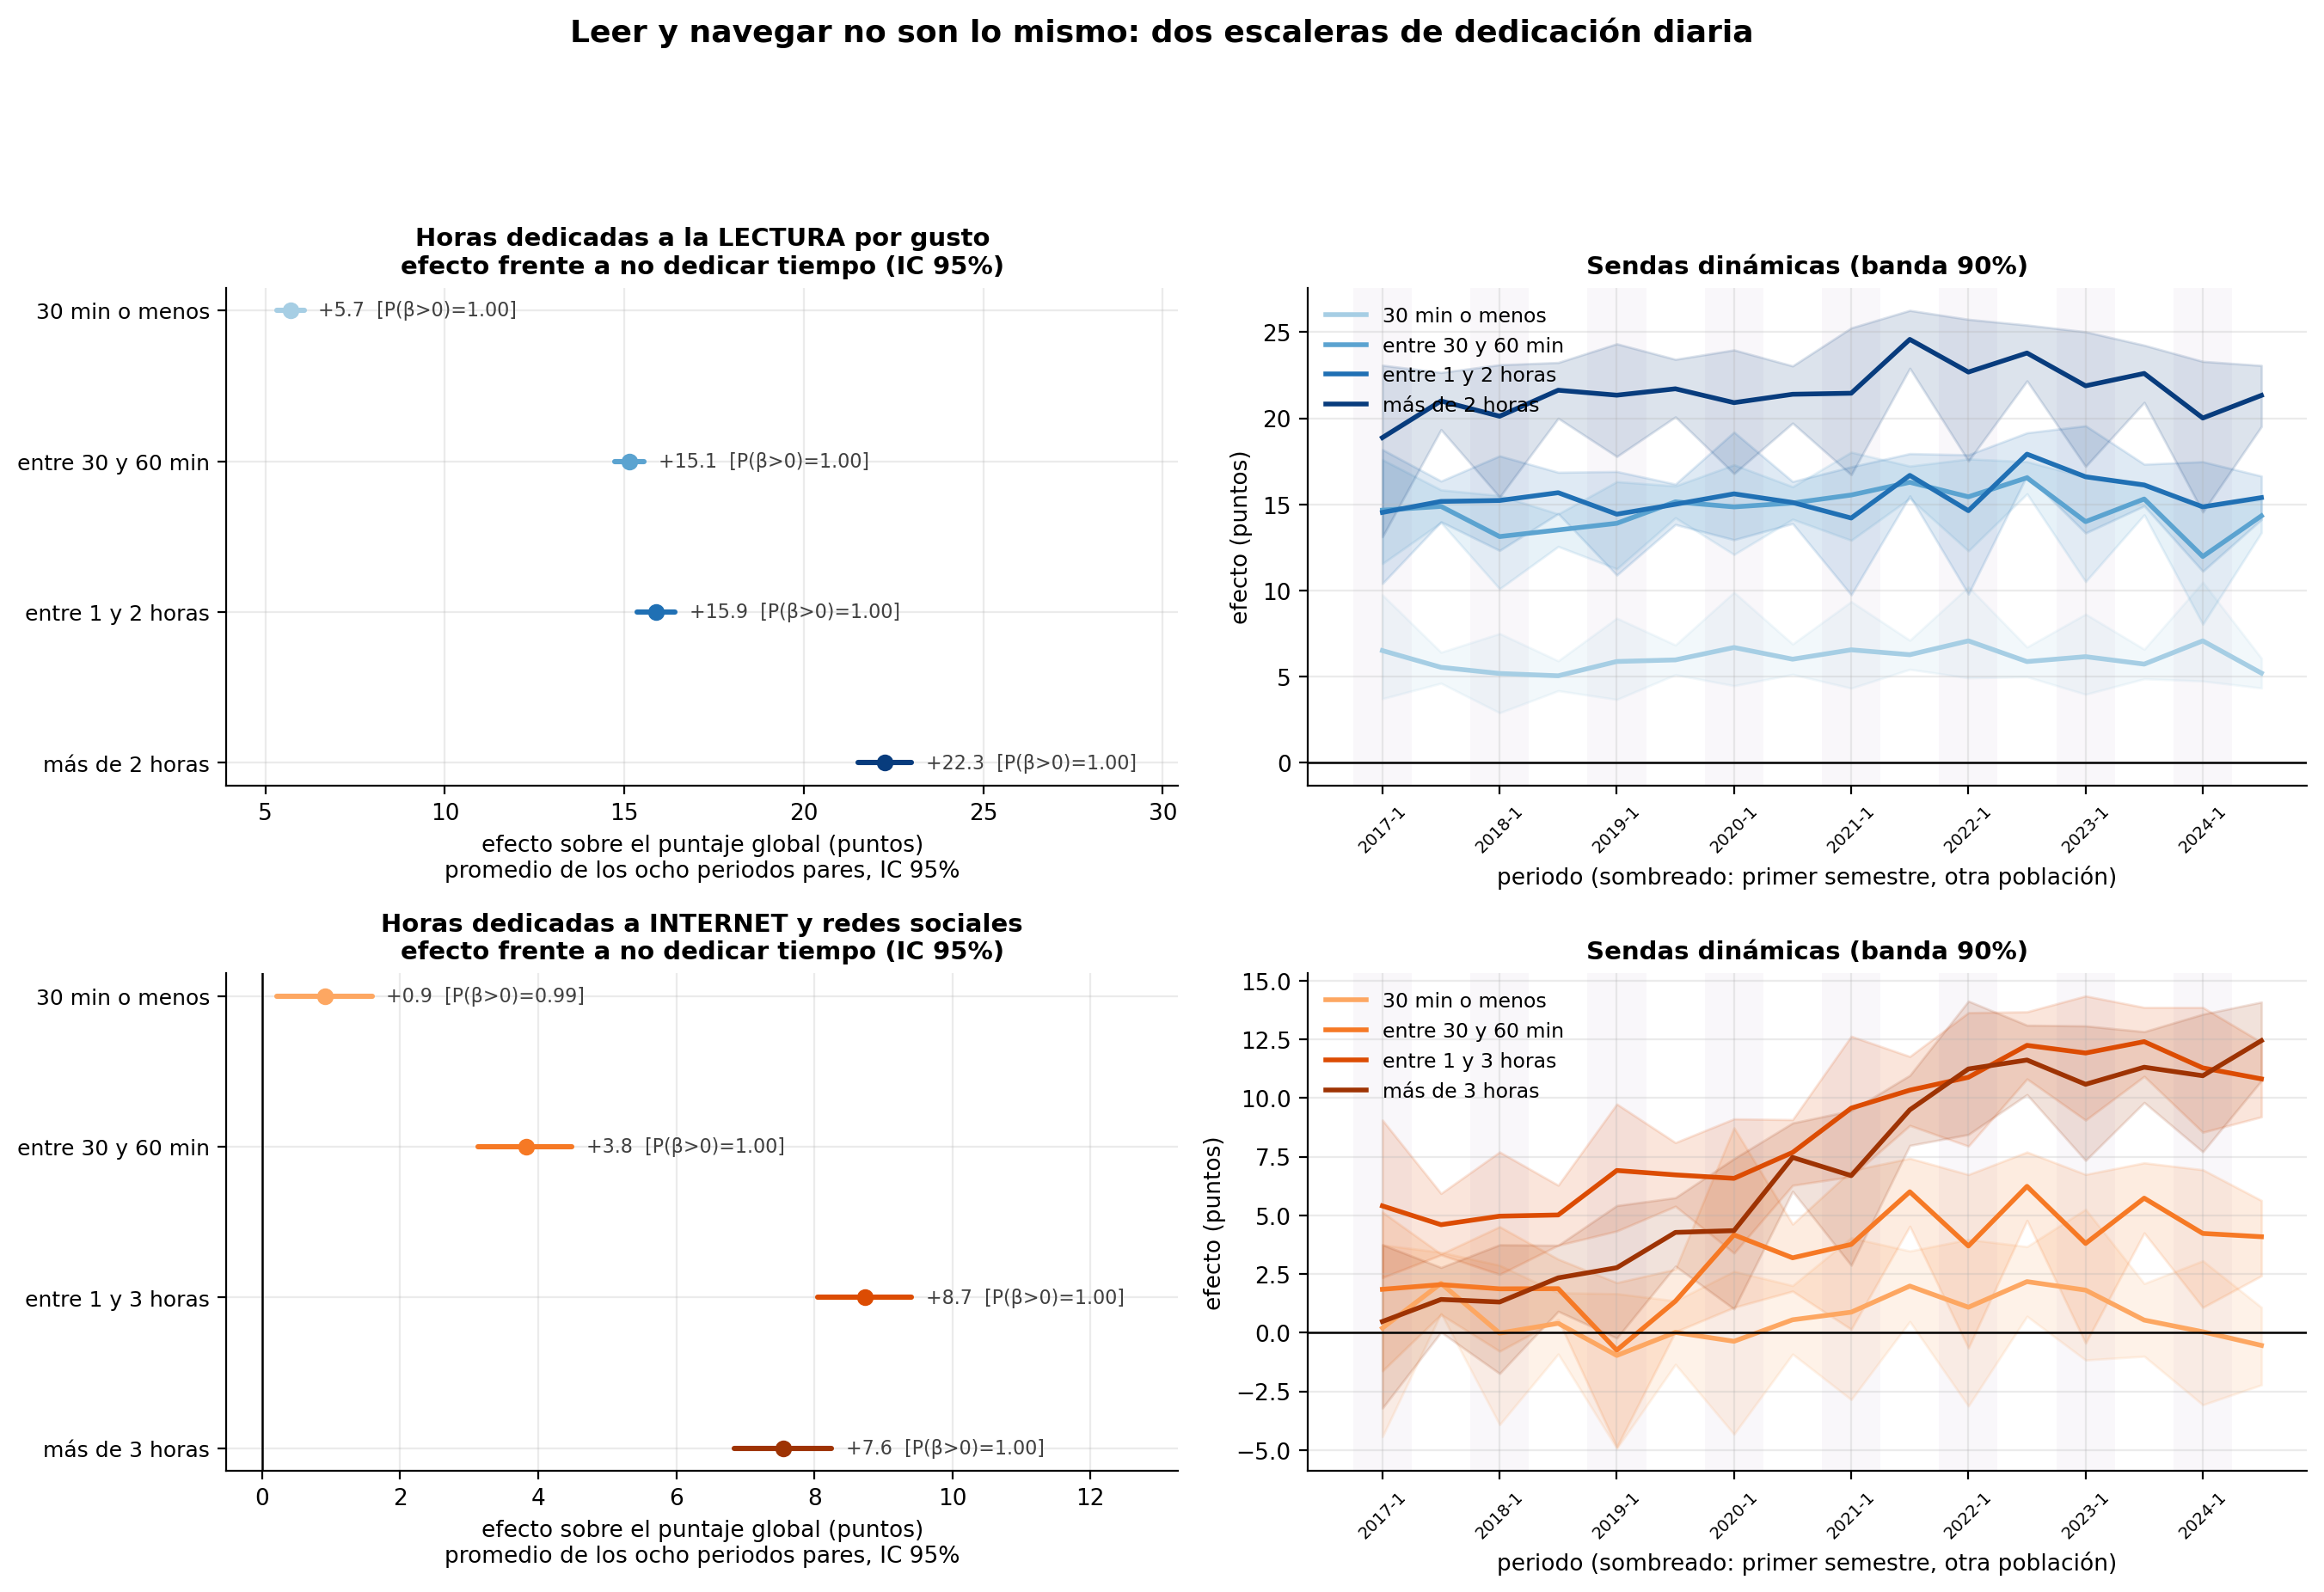

**fig09_contexto_muni.png**

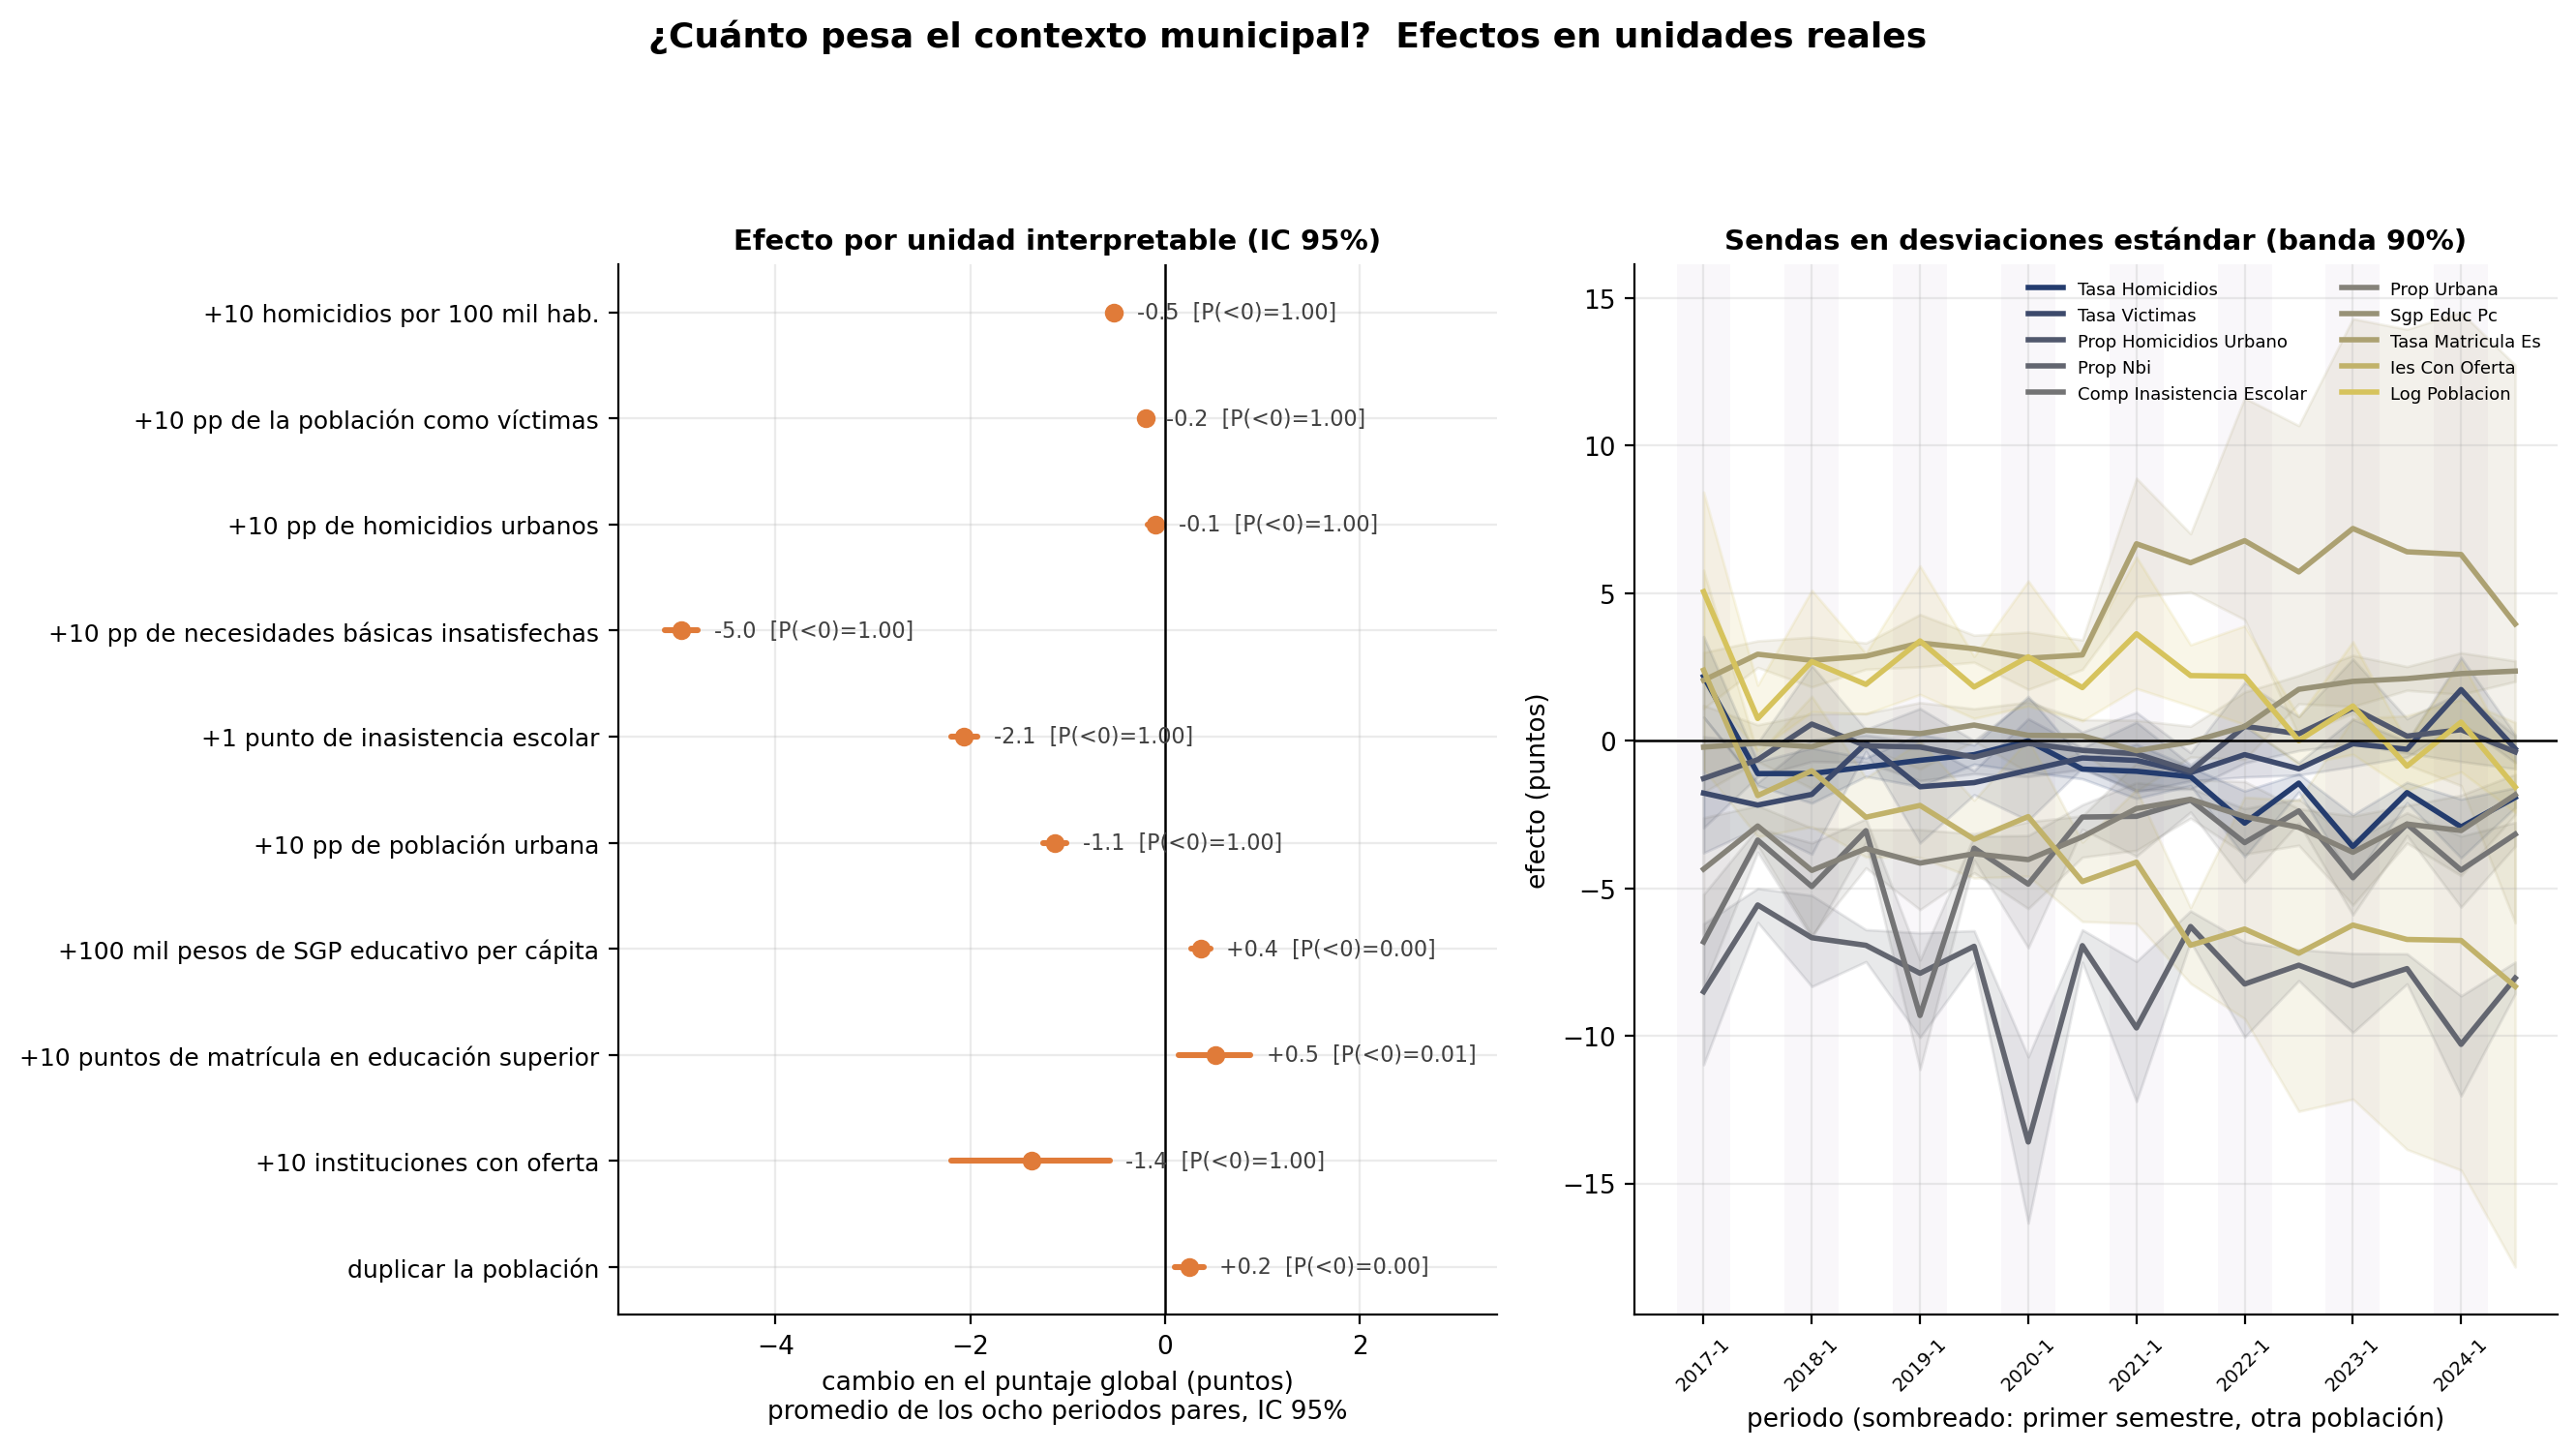

**fig10_contexto_depto.png**

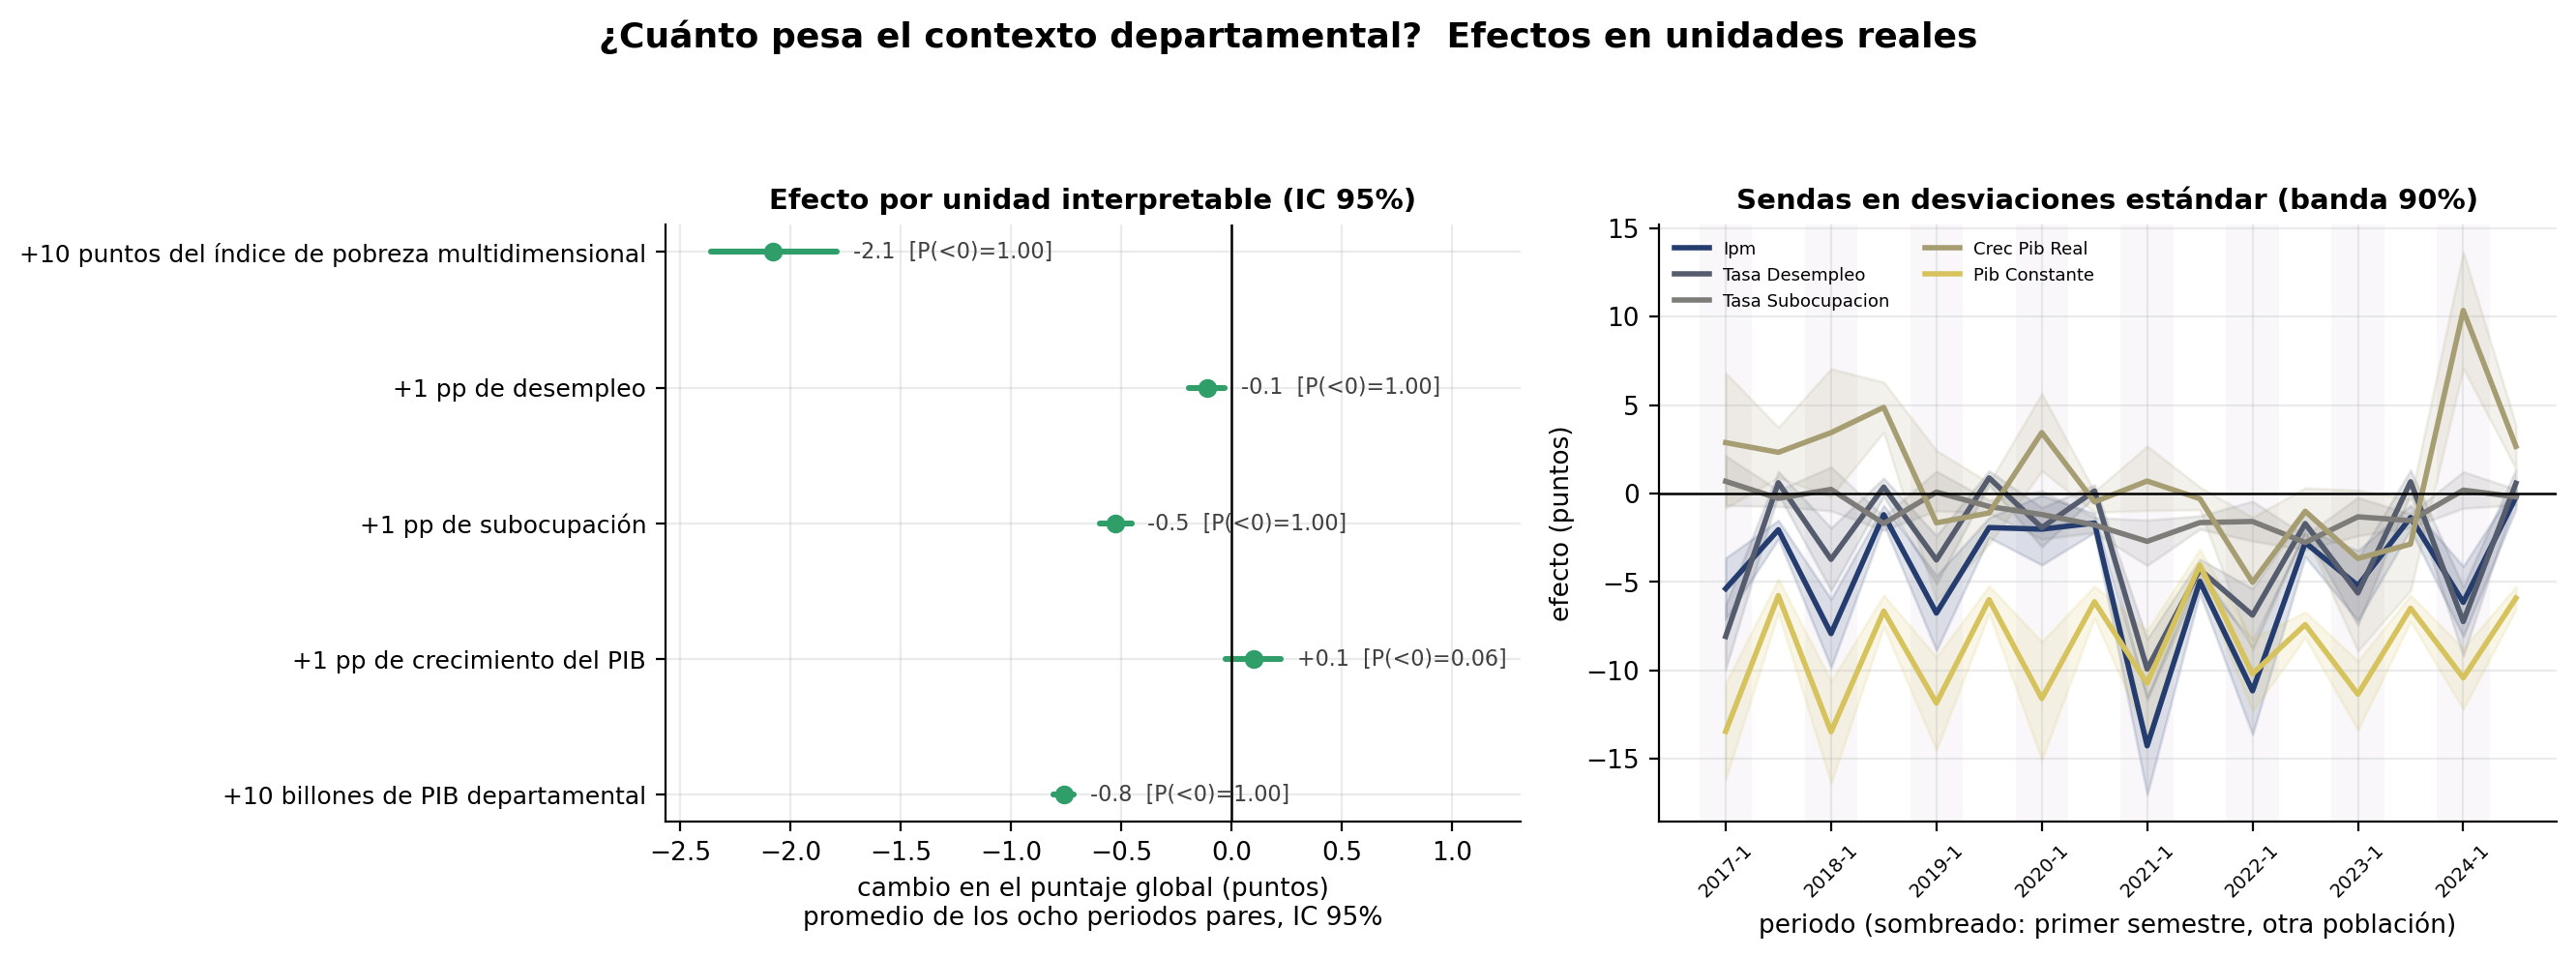

**fig11_cambio_temporal.png**

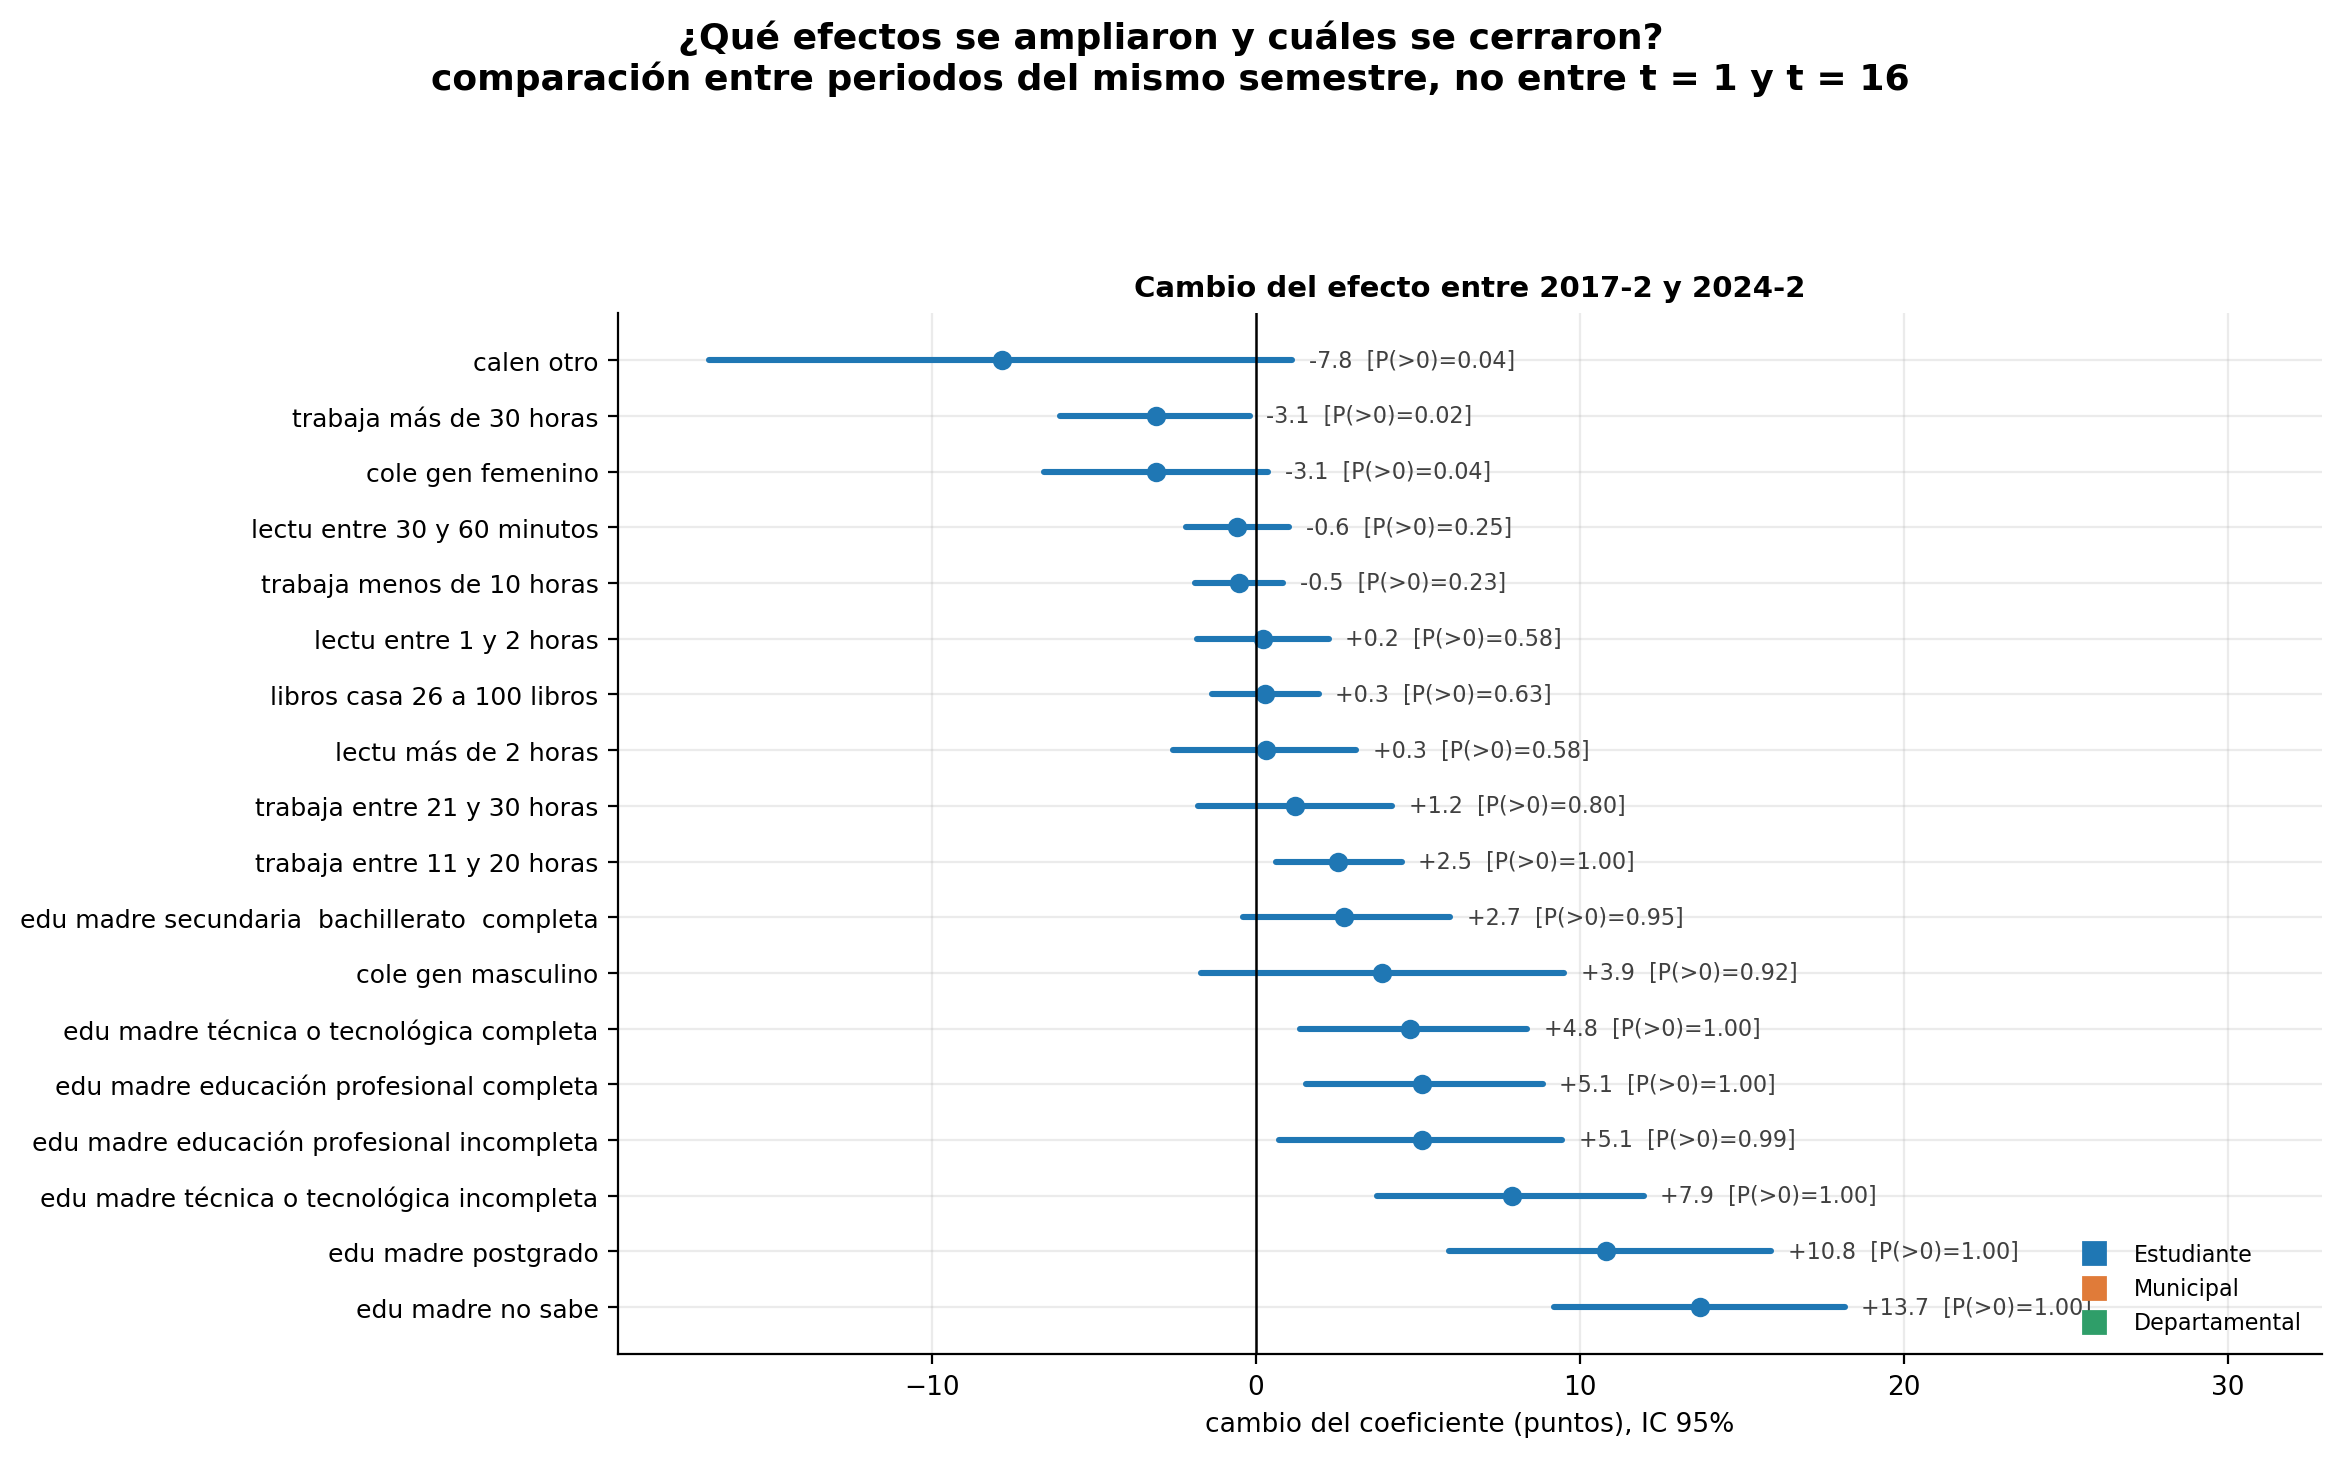

**fig12_ranking.png**

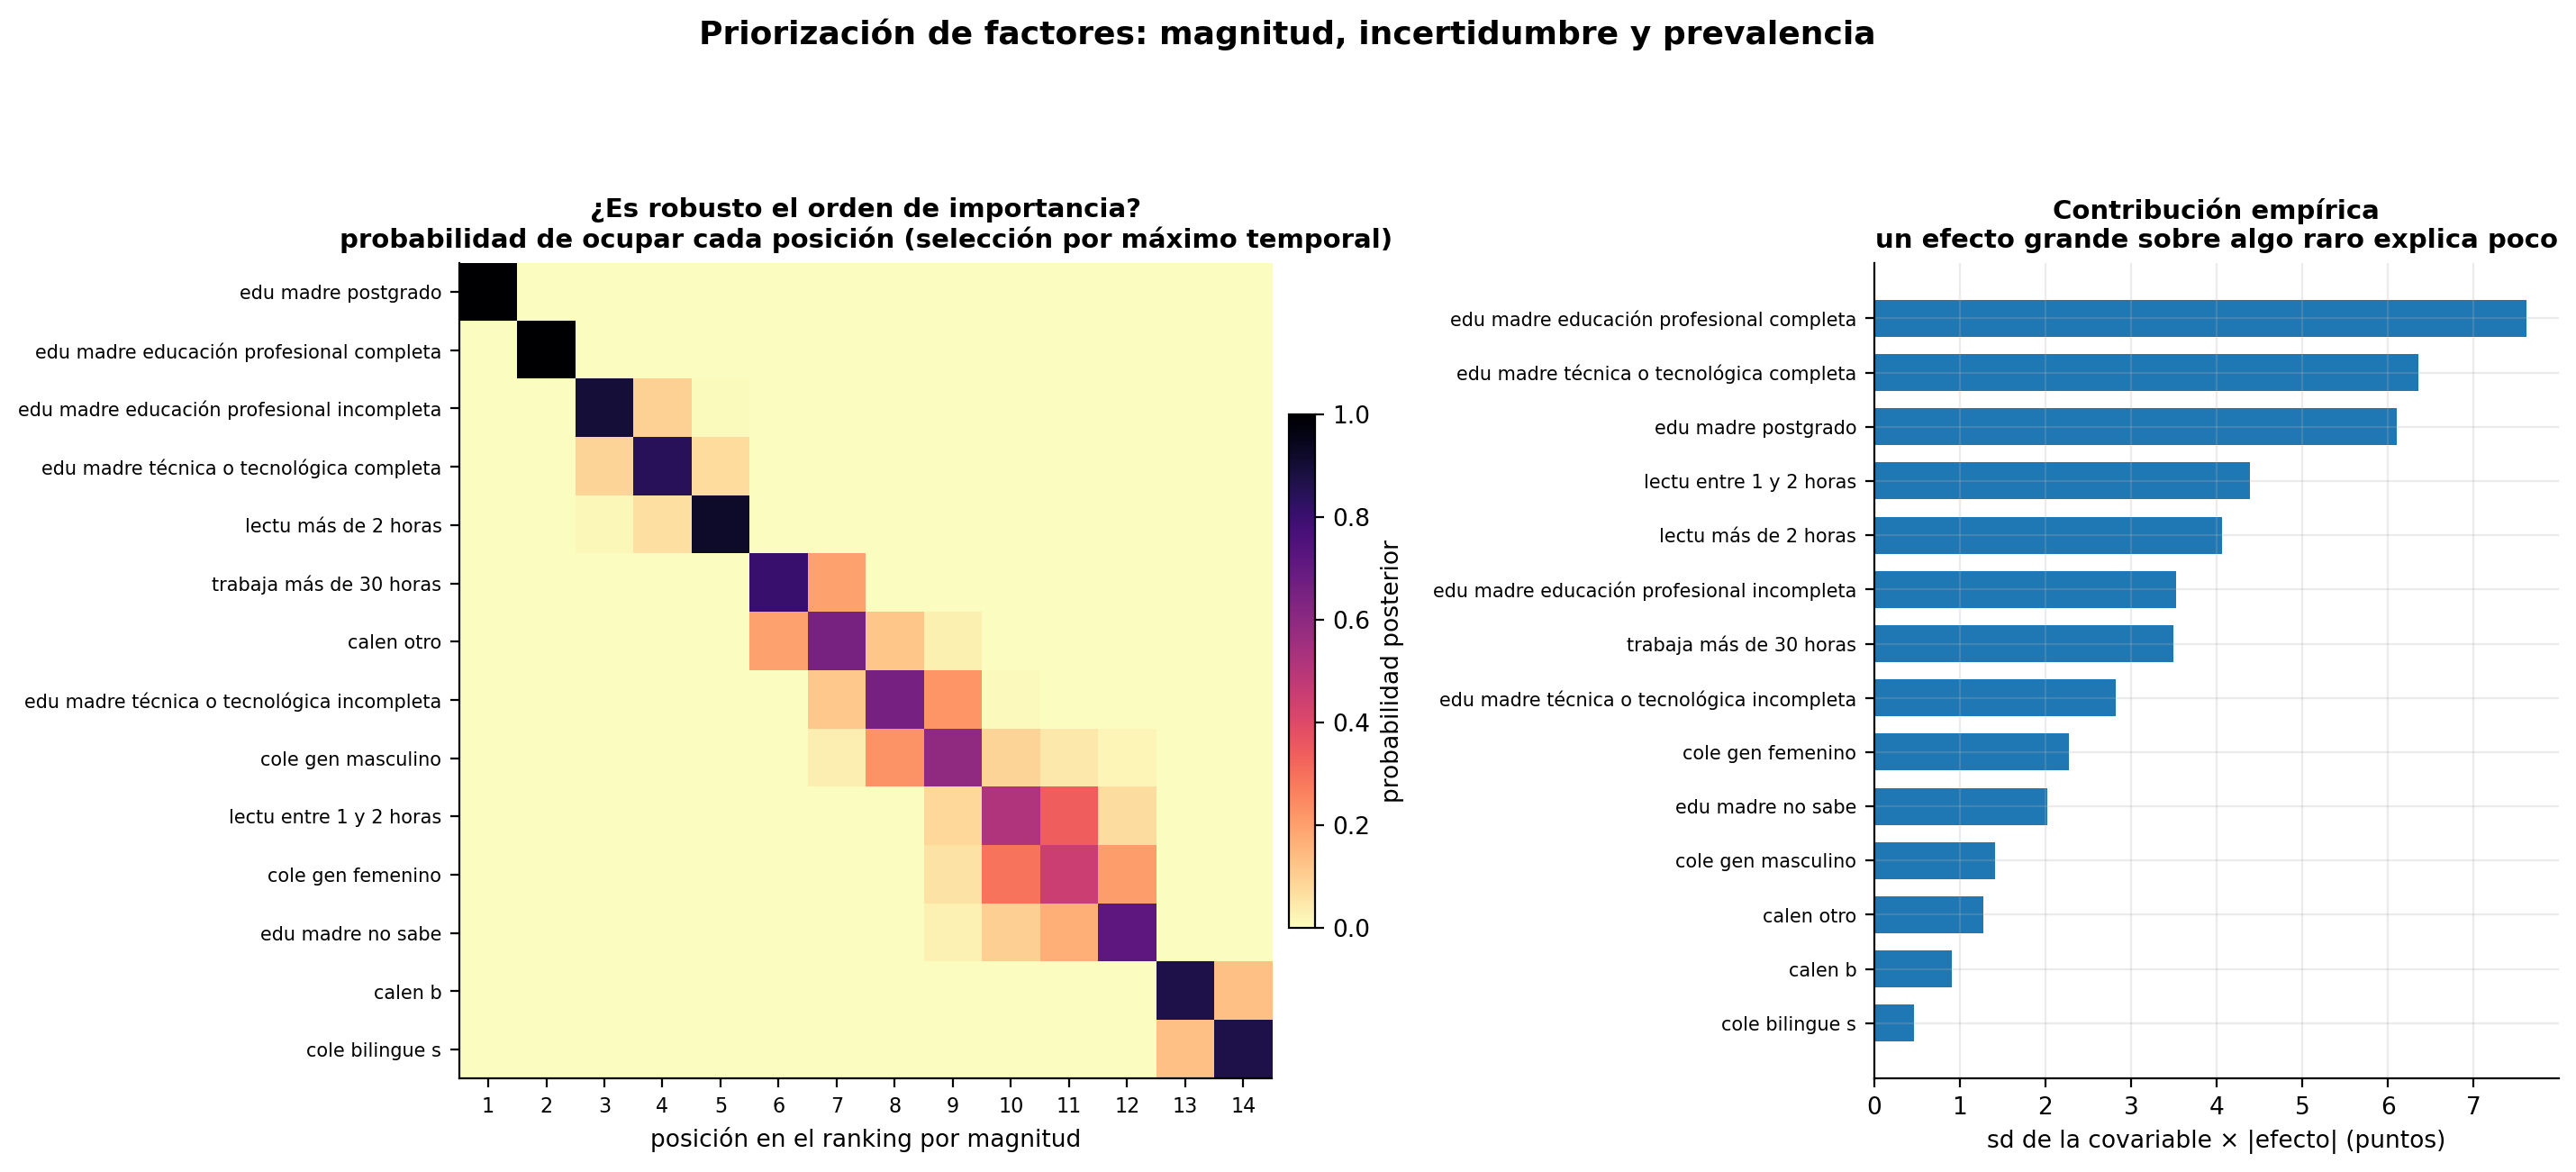

**fig13_faltantes.png**

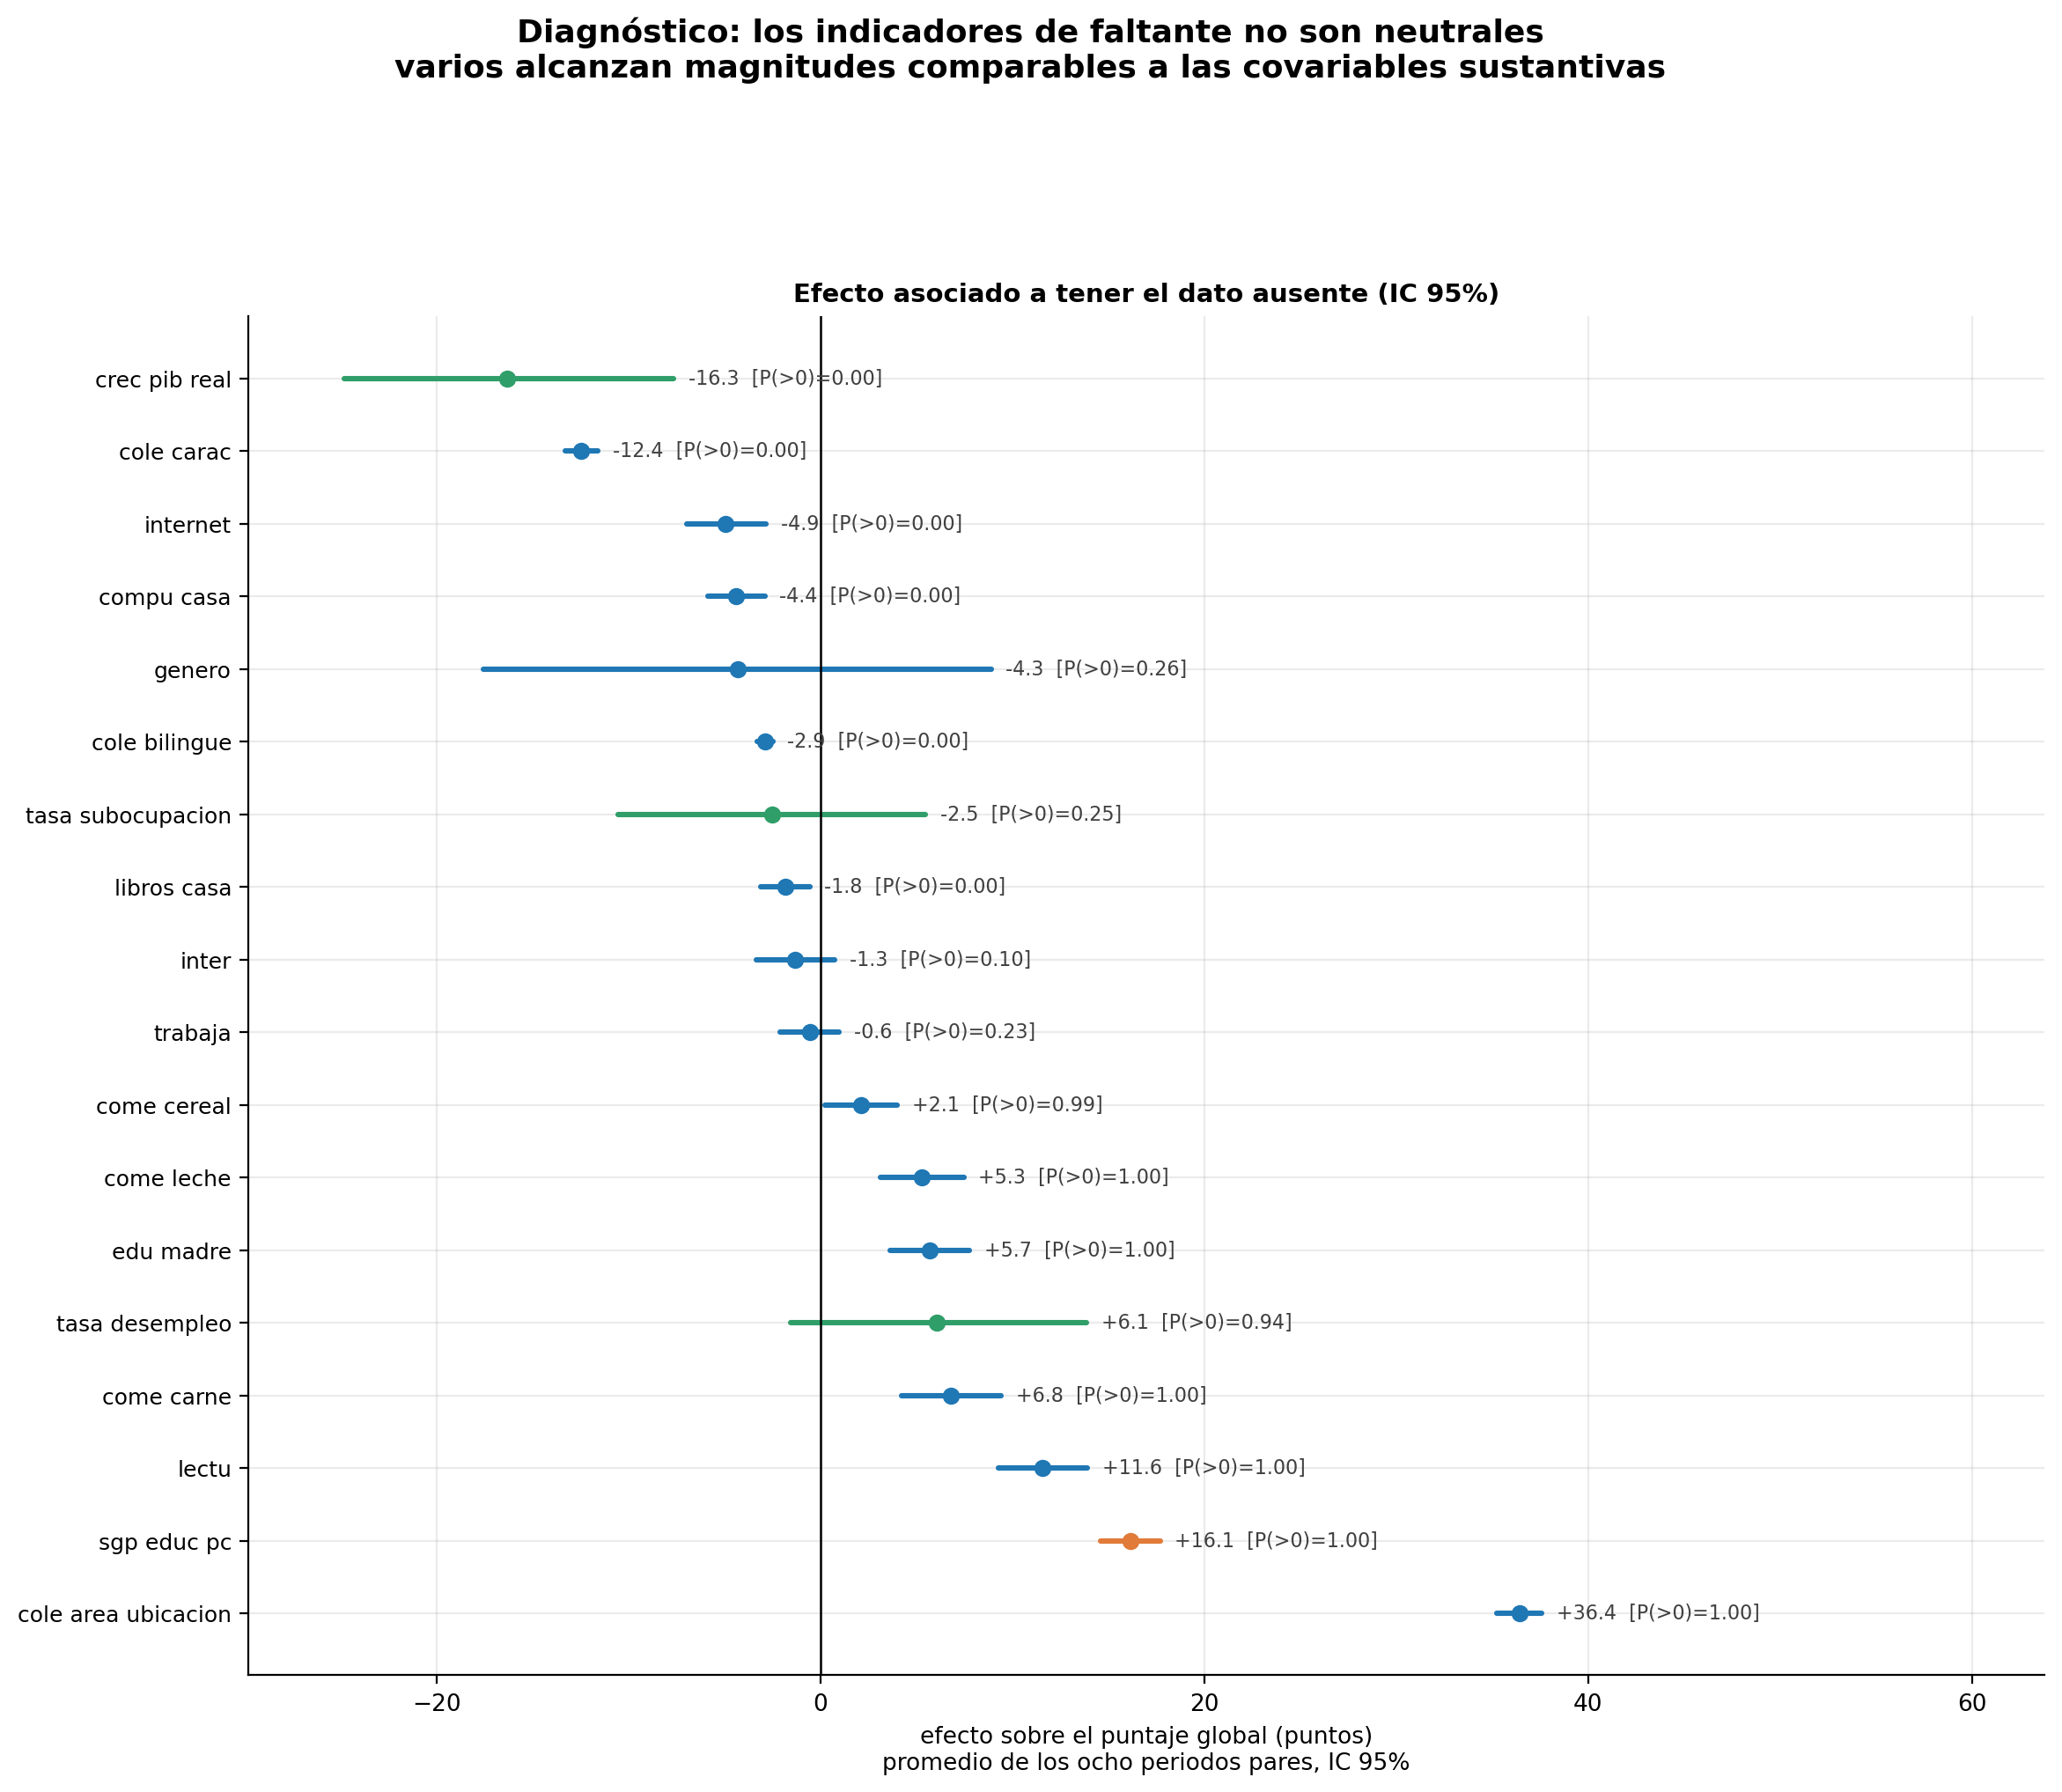

In [ ]:
from IPython.display import Image, display, Markdown
FIGS = RAIZ / "resultados_M4"
orden = sorted(FIGS.glob("figR*.png")) + sorted(
    f for f in FIGS.glob("fig*.png") if not f.name.startswith("figR"))
for f in orden:
    display(Markdown(f"**{f.name}**"))
    display(Image(filename=str(f), width=980))

## Solución de problemas

| Síntoma | Causa y remedio |
|---|---|
| `SSLError: CERTIFICATE_VERIFY_FAILED` al instalar algo | Proxy con certificado autofirmado, típico de red universitaria. Ya no aplica: el pipeline no necesita instalar nada. Si algún día hiciera falta, usar `pip install X --trusted-host pypi.org --trusted-host files.pythonhosted.org`, o `conda install -c conda-forge X`. |
| `FileNotFoundError: Falta .../prep_M4.npz` | El 17 o el 19 corrieron sin el caché. Activar `16_preparacion_M4.py` y reejecutar. |
| `FALTA colombia_departamentos.geojson` | Activar `18_geografia_M4.py`: lo genera él a partir del zip del MGN. |
| `MemoryError` en el 16 | `nivel_M4.npz` necesita ~1 GB de pico. Bajar `S_SUB` de 400 a 200 en la cabecera del módulo 16. |
| Los mapas salen todos grises | Los códigos no empalman. Revisar que `muni_ids.csv` esté en `export_python/`, reejecutar el 16 y luego el 18, que imprime el diagnóstico de empalme. |
| El 18 avisa de municipios sin geometría | Esperado: `27086` (Belén de Bajirá) no tiene polígono propio en el MGN por el litigio Chocó–Antioquia. Queda en gris. |
| `KeyError: '...' no esta en estandar_params.csv` | Falta el CSV en `export_python/`, o la variable se eliminó por el filtro QR de la Etapa 1. El 20 falla a propósito en vez de escalar el efecto con sd = 1 en silencio. |
| `KeyError: ... no estan en theta_labels` | Alguna categoría de referencia cambió de nombre en la Etapa 1. El 20 lo comprueba antes de dibujar, así que no quedan figuras a medias: corregir el nombre en la lista que indica el mensaje. |
| `RuntimeError: phi2 no coincide con resumen_M4.txt` | El binario `S x 3` se está leyendo como `(3, S)`. Debe ser `reshape((S, 3), order="F").T`. |
| Un módulo tarda mucho más de lo indicado | `F.bin` está en OneDrive y se está sincronizando. Mover la carpeta a disco local. |

**Ejecutar un módulo suelto**, sin el cuaderno, desde el terminal:

```
set M4_RAIZ=C:\ruta\a\Modelo 4\Analisis Python
python 19_panorama_M4.py
```